In [1]:
!pip install -q "keras==3.15.0"

In [1]:
from google.colab import drive, files
drive.mount('/content/drive')
import os, shutil, unicodedata
norm = lambda s: ' '.join(unicodedata.normalize('NFC', s).lower().split())
def entrar(partes):
    r = '/content/drive/MyDrive'
    for p in partes:
        r = r + '/' + [h for h in os.listdir(r) if norm(h) == norm(p)][0]
    return r
base = ['DOCUMENTOS', 'FACULTAD DE INGENIERIA', 'Linea de Investigación - Biomimesis', 'Biomimesis - GitHub']
d5, d6 = entrar(base + ['Version 31 - 5 bases']), entrar(base + ['Version 31 - 6 bases'])
os.chdir(d6)
for f in ['tabla2_masson_NT.csv', 'tabla4_masson_HT.csv', 'masson2011_curvas_medias.csv']:
    if not os.path.exists(f):
        shutil.copy(d5 + '/' + f, f)
if not os.path.exists('historial_entrenamiento_v28_6.csv'):
    print('Subí historial_entrenamiento_v28_6.csv:')
    files.upload()
import keras
print('Keras', keras.__version__, '| carpeta:', os.getcwd())
print(sorted(os.listdir()))


Mounted at /content/drive
Subí historial_entrenamiento_v28_6.csv:


Saving historial_entrenamiento_v28_6.csv to historial_entrenamiento_v28_6.csv
Saving masson2011_curvas_medias.csv to masson2011_curvas_medias (1).csv
Saving tabla2_masson_NT.csv to tabla2_masson_NT (1).csv
Saving tabla4_masson_HT.csv to tabla4_masson_HT (1).csv
Keras 3.15.0 | carpeta: /content/drive/MyDrive/DOCUMENTOS/FACULTAD DE INGENIERIA/Linea de Investigación - Biomimesis/Biomimesis - GitHub/Version 31 - 6 bases
['curva_j_v31_6bases.ipynb', 'estudio_pared_v31_5.csv', 'historial_entrenamiento_v28_6.csv', 'historial_entrenamiento_v28_6.gsheet', 'masson2011_curvas_medias (1).csv', 'masson2011_curvas_medias.csv', 'masson2011_curvas_medias.gsheet', 'modelo_rn_curva_j_v28_6.keras', 'scalers_curva_j_v28_6.pkl', 'tabla2_masson_NT (1).csv', 'tabla2_masson_NT.csv', 'tabla2_masson_NT.gsheet', 'tabla4_masson_HT (1).csv', 'tabla4_masson_HT.csv', 'tabla4_masson_HT.gsheet']


In [2]:
import keras, os
print('Keras', keras.__version__)
print(os.getcwd())
print(sorted(os.listdir()))

Keras 3.15.0
/content/drive/MyDrive/DOCUMENTOS/FACULTAD DE INGENIERIA/Linea de Investigación - Biomimesis/Biomimesis - GitHub/Version 31 - 6 bases
['curva_j_v31_6bases.ipynb', 'estudio_pared_v31_5.csv', 'historial_entrenamiento_v28_6.csv', 'historial_entrenamiento_v28_6.gsheet', 'masson2011_curvas_medias (1).csv', 'masson2011_curvas_medias.csv', 'masson2011_curvas_medias.gsheet', 'modelo_rn_curva_j_v28_6.keras', 'scalers_curva_j_v28_6.pkl', 'tabla2_masson_NT (1).csv', 'tabla2_masson_NT.csv', 'tabla2_masson_NT.gsheet', 'tabla4_masson_HT (1).csv', 'tabla4_masson_HT.csv', 'tabla4_masson_HT.gsheet']


# V31 — Diseño fabricable: MCO y red neuronal

**Qué hace este cuaderno.** Diseña el injerto de dos maneras:
- por **número de láminas** de cada material, con `C_LAM = 20` láminas como escala (configuración adoptada);
- por **espesor de capa** (Celdas 23 a 26). Cada material j es una capa de espesor h_j [mm] y módulo equivalente E_j [MPa]. Por la ley de Laplace, 1 mm del material j aporta a_j(λ) = E_j / (R_ref·k_j²) · max(0, λ − k_j).

**MCO y red, siempre los dos.** Para cada curva se calculan las láminas de dos maneras y las dos se comparan con la curva original:
- **MCO** (mínimos cuadrados): la cuenta exacta, `mco(Y)`;
- **red neuronal**: `predecir(Y)`, una sola evaluación.

Ninguna de las dos reemplaza a la otra: se muestran juntas, con su error contra la curva original (Celdas 12 a 19, 23 y 24).

**Diseño fabricable por espesor.** Minimiza el error punto a punto máximo contra la curva de la arteria (minimax), con dos restricciones:
- **pared:** h_1 + … + h_N ≤ `PARED_MAX_MM` (por defecto 1 mm, la pared de una carótida);
- **capa mínima:** cada capa vale 0 (material no usado) o al menos `ESP_MIN_MM` (por defecto 0,1 mm).

Se resuelve por programación lineal entera mixta (HiGHS, incluido en SciPy), con una variable binaria por material. Con `ESPESOR_DISCRETO_MM = t`, cada capa es además un número entero de láminas de espesor t.

**Redes.** Se usan las redes ya entrenadas, sin reentrenar:
- con 5 materiales, `v27_5`;
- con 6, `v28_6`.

Copiar en esta carpeta sus tres archivos (`modelo_rn_curva_j_….keras`, `scalers_curva_j_….pkl`, `historial_entrenamiento_….csv`). Las redes se entrenaron con 10 láminas; sus salidas se multiplican por `C_LAM / 10`, lo que es una identidad exacta.

**Celda 0.**
- `N_BASES`: 5 o 6.
- `C_LAM`: 20 (escala de láminas).
- `PARED_MAX_MM`, `ESP_MIN_MM`, `ESPESOR_DISCRETO_MM`: las restricciones de fabricación por espesor.
- `E_MAT_MPA`: los módulos de los materiales. Con `None` se usan los de `E_REF`, elegidos con la Celda 26 para que cumpla la mayor cantidad de sujetos con pared de 1 mm y capa mínima de 0,1 mm (6 materiales: 36 de 41).

**Celdas de diseño.**
- **19 — Diseñador de injerto.** Curva → láminas de cada material con el MCO y con la red, y el error de cada una contra la curva.
- **23 — Diseño fabricable.** Rediseña los 41 sujetos, las 4 curvas medias e y1, y2.
- **24 — y2, Mean HT e y1.** Curva original, MCO, red y diseño fabricable.
- **25 — Estudio de pared.** Sujetos que cumplen según la pared máxima y el espesor mínimo de capa. El cuaderno que se corre en segundo lugar compara 5 y 6 materiales.
- **26 — Módulos E (opcional, ≈ 1 h).** Con `OPTIMIZAR_E = True` busca los E que maximizan los sujetos que cumplen. El resultado se copia en `E_REF`.

**Para correr.** Las Celdas 0 a 11 siempre; después, las Celdas 12 a 22 (evaluación de la red) o directamente 23 a 25 (diseño fabricable).

**Archivos en esta carpeta:** `tabla2_masson_NT.csv`, `tabla4_masson_HT.csv` y `masson2011_curvas_medias.csv`.

## Celda 0 — Configuración (ejecutar siempre primero)

In [4]:
# CELDA 0: CONFIGURACIÓN (ejecutar siempre primero)
import os
import numpy as np

N_BASES = 6                      # ← número de bases (materiales): 4, 5 o 6. Cada número de bases tiene su propia red
VERSION = f"v31_{N_BASES}"
SEED = 42
DIR_MASSON = "."                 # tablas de Masson en la misma carpeta que el notebook
ENTRENAR = "auto"                # "auto": carga la red de MODELO_RED si sus archivos están en la carpeta y, si no, la entrena;
                                 # True: entrena siempre; False: carga siempre (error si faltan los archivos)
MODELO_RED = {5: "v27_5", 6: "v28_6"}.get(N_BASES, f"v28_{N_BASES}")   # red ya entrenada que se carga (mismos nudos)
if ENTRENAR == "auto":                                           # busca primero la red de MODELO_RED y después la de esta versión
    _hay = [m for m in (MODELO_RED, VERSION) if os.path.exists(f"modelo_rn_curva_j_{m}.keras")]
    ENTRENAR, MODELO_RED = (False, _hay[0]) if _hay else (True, VERSION)

# Diseño: N_BASES materiales (4 a 6), cada base = UNA lámina, A_j(λ) = S_j·max(0, λ − k_j), con S_j = PEND_MAX_j / C_LAM_j
NUDOS_REF = {4: [0.834, 1.0264, 1.108, 1.1416],                   # nudos minimax con láminas ≥ 0 en todo el espacio (franja de trabajo)
             5: [0.8291, 1.0231, 1.0942, 1.1273, 1.1472],         # evolución diferencial + Nelder–Mead, PESO_NEG = 10
             6: [0.8271, 1.0219, 1.0867, 1.1197, 1.1391, 1.1531]}
OPTIMIZAR_NUDOS = False          # True: re-optimiza los nudos (se hace solo si cond(A) ≥ UMBRAL_COND, faltan en NUDOS_REF o hay láminas < 0)
UMBRAL_COND = 25.0               # cota de cond(A) (columnas normalizadas) que deben cumplir los nudos
PESO_NEG = 10.0                  # peso de la penalización por láminas negativas del MCO libre al elegir los nudos (evaluada en todo el espacio)
SIGNO_ESTRICTO = True            # True: la Celda 3 exige 0 curvas del espacio de trabajo con láminas negativas
C_LAM = 20                       # máximo de láminas por material (configuración adoptada: 20) (solo para las Celdas 3 a 22): un número para todos o una lista de N_BASES valores; no requiere reentrenar
C_LAM_RED = 10.0                 # láminas con que se entrena la red (no cambiar)

ERROR_MAX_PCT = 3.0              # criterio: error punto a punto ≤ 3 % del rango de la curva
SUJETO_Y1, SUJETO_Y2 = "NT16", "HT09"                            # sujetos de partida de las curvas límite
# y1: ley de Masson con la geometría y las fibras de NT16 y estos 5 parámetros (dentro del rango de los 41 sujetos),
#     elegidos para que y1(X_MIN) = mín. de los 41 sujetos en X_MIN (HT10, 0,17 kPa) y y1 ≤ los 41 sujetos en todo el dominio
PARAM_Y1 = {"c_kPa": 38.4794, "c1_kPa": 6.4381, "c1circ_kPa": 6.8457, "c2circ": 10.82315, "Tm_kPa": 55.0624}
LAMBDA_Y2, Y2_MAX = 1.10, 60.0   # y2 = HT09 hasta LAMBDA_Y2 y luego llega a Y2_MAX [kPa] en X_MAX
H_PARED_MM, N_RADIAL = 0.6, 60   # espesor supuesto y puntos de cuadratura de P_pared
X_MIN, X_MAX, N_PTS = 1.02, 1.16, 999
X = np.linspace(X_MIN, X_MAX, N_PTS)
FRAC_SUJETOS_TEST = 0.25
X_INICIO_CONVEXIDAD, TOL_FORMA_REL = 1.05, 0.01                  # control de forma J
TOL_CLASE_NRMSE, N_NUDOS_CLASE, NUDO_MIN_CLASE = 2.0, 40, 0.85   # control de clase a la entrada
ESPESOR_LAMINA_MM = 0.10         # espesor de referencia para pasar K [N/m] a E [MPa]
# Diseño fabricable (Celdas 23 a 26): cada material es una capa de espesor h_j [mm]; 1 mm del material j aporta
#   a_j(λ) = E_j / (R_ref·k_j²) · max(0, λ − k_j)  [kPa]   (ley de Laplace; E_j = módulo equivalente [MPa])
PARED_MAX_MM = 1.0               # ← espesor máximo de la pared (suma de las capas) [mm]
ESP_MIN_MM = 0.10                # ← espesor mínimo de una capa [mm]: cada capa es 0 (material no usado) o ≥ ESP_MIN_MM
ESPESOR_DISCRETO_MM = None       # None: espesor continuo; un número (p. ej. 0.1): capas de láminas enteras de ese espesor
E_REF = {5: [0.2433, 2.2237, 2.3802, 6.0183, 8.7886],         # módulos [MPa] que maximizan los sujetos que cumplen
         6: [0.177, 1.3282, 4.8612, 2.7239, 12.9384, 6.3525]}  #   con PARED_MAX_MM = 1 y ESP_MIN_MM = 0,1 (Celda 26; 6 bases: 36/41)
E_MAT_MPA = None                 # None: E_REF[N_BASES]; o una lista de N_BASES módulos [MPa]
ETQ_X, ETQ_Y = r"$\lambda_\theta$ ($\propto$ diámetro)", r"$P_{pared} = P_i - P_a$ [kPa]"

_v = VERSION if ENTRENAR else MODELO_RED
ARCHIVO_MODELO, ARCHIVO_SCALERS, ARCHIVO_HISTORIAL = (f"modelo_rn_curva_j_{_v}.keras", f"scalers_curva_j_{_v}.pkl",
                                                      f"historial_entrenamiento_{_v}.csv")
print(f"✅ {VERSION} | λθ ∈ [{X_MIN}, {X_MAX}] | {N_BASES} bases | pared ≤ {PARED_MAX_MM:g} mm, capa ≥ {ESP_MIN_MM:g} mm"
      f"{'' if ESPESOR_DISCRETO_MM is None else f' (láminas de {ESPESOR_DISCRETO_MM:g} mm)'} | "
      f"red: {'se entrena' if ENTRENAR else 'se carga de ' + ARCHIVO_MODELO}")

✅ v31_6 | λθ ∈ [1.02, 1.16] | 6 bases | pared ≤ 1 mm, capa ≥ 0.1 mm | red: se carga de modelo_rn_curva_j_v28_6.keras


## Celda 1 — Modelo de Masson et al. (2011), curvas P_pared de los 41 sujetos y curvas límite

In [5]:
# CELDA 1: MODELO DE MASSON ET AL. (2011) Y CURVAS P_pared(λθ) DE LOS 41 SUJETOS
# P_pared = Pi − Pa = ∫ (σθθ − σrr)/r dr sobre el espesor; λθ en r_m (∝ diámetro).
import os
import numpy as np
import pandas as pd

COLS_PARAM = ["Rm_mm", "Theta0_deg", "lambda_ax", "c_kPa", "c1_kPa", "c2", "c1circ_kPa", "c2circ", "alpha_deg",
              "Tm_kPa", "lambda0", "lambda_m", "a_kPa", "b"]


def sigma_masson(lt, p, restar_Pa=True):
    """σθθ(λθ) [kPa] en r_m: elastina neo-Hookeana + 4 familias de colágeno + tono activo."""
    lt = np.asarray(lt, float)
    lz, al = p["lambda_ax"], np.deg2rad(p["alpha_deg"])
    lam_d = np.sqrt(lt ** 2 * np.sin(al) ** 2 + lz ** 2 * np.cos(al) ** 2)
    suma = np.zeros_like(lt)
    for lam_k, c1, c2, ang in [(lz * np.ones_like(lt), p["c1_kPa"], p["c2"], 0.0), (lt, p["c1circ_kPa"], p["c2circ"], np.pi / 2),
                               (lam_d, p["c1_kPa"], p["c2"], al), (lam_d, p["c1_kPa"], p["c2"], -al)]:
        E = lam_k ** 2 - 1.0
        suma = suma + c1 * E * np.exp(c2 * E ** 2) * np.sin(ang) ** 2
    activo = p["Tm_kPa"] * lt * (1.0 - ((p["lambda_m"] - lt) / (p["lambda_m"] - p["lambda0"])) ** 2)
    s = -p["c_kPa"] * (1.0 / (lt * lz)) ** 2 + p["c_kPa"] * lt ** 2 + lt ** 2 * suma + activo
    return s - p["a_kPa"] * np.exp(p["b"]) if restar_Pa else s


def curva_objetivo(lt_m, p):
    """P_pared(λθ en r_m) [kPa] con la cinemática de Masson (ángulo de apertura Θ0, λz fijo, incompresible)."""
    lt_m = np.asarray(lt_m, float)
    Th, lz, Rm = np.deg2rad(p["Theta0_deg"]), p["lambda_ax"], p["Rm_mm"]
    rm = lt_m * Th * Rm / np.pi
    rr = (rm - H_PARED_MM)[:, None] + H_PARED_MM * np.linspace(0.0, 1.0, N_RADIAL)[None, :]
    R = np.sqrt(np.maximum(Rm ** 2 - (np.pi * lz / Th) * (rm[:, None] ** 2 - rr ** 2), 1e-12))
    return np.trapezoid(sigma_masson(np.pi * rr / (Th * R), p, restar_Pa=False) / rr, rr, axis=1)


def diagnostico_forma(y, x=X):
    """(monótona, convexa desde X_INICIO_CONVEXIDAD), con tolerancia relativa a la pendiente máxima."""
    p = np.diff(y) / np.diff(x)
    tol = TOL_FORMA_REL * max(float(np.abs(p).max()), 1e-9)
    return bool(p.min() >= -tol), bool(np.diff(p)[x[1:-1] >= X_INICIO_CONVEXIDAD].min() >= -tol)


POB = pd.concat([pd.read_csv(f"{DIR_MASSON}/{f}").assign(grupo=g) for f, g in
                 [("tabla2_masson_NT.csv", "NT"), ("tabla4_masson_HT.csv", "HT")]], ignore_index=True)
POB["id"] = POB["grupo"] + POB["subject"].map("{:02d}".format)
POB_Y = np.array([curva_objetivo(X, r) for _, r in POB.iterrows()])

# Sujetos reservados para test (estratificado por grupo): no entran al generador
_rng = np.random.default_rng(SEED)
POB["test"] = False
for g in ("NT", "HT"):
    i_g = POB.index[POB["grupo"] == g].to_numpy()
    POB.loc[_rng.choice(i_g, size=int(round(FRAC_SUJETOS_TEST * len(i_g))), replace=False), "test"] = True
MASK_TEST = POB["test"].to_numpy()
MASK_TRAIN = ~MASK_TEST

# Curvas límite: y1 = ley de Masson (geometría de NT16 con PARAM_Y1), por debajo de los 41 sujetos y con y1(X_MIN) = mín. medido;
# y2 = HT09 + a·(exp(b·E²) − 1), E = (λ/LAMBDA_Y2)² − 1 > 0, con b = c2circ de HT09 y a tal que y2(X_MAX) = Y2_MAX
_p1 = POB.loc[POB["id"] == SUJETO_Y1].iloc[0].copy()
for _k, _v in PARAM_Y1.items():
    _p1[_k] = _v
Y1 = curva_objetivo(X, _p1)
_y2 = POB_Y[(POB["id"] == SUJETO_Y2).to_numpy()][0]
_g = np.exp(float(POB.loc[POB["id"] == SUJETO_Y2, "c2circ"].iloc[0]) * np.maximum(0.0, (X / LAMBDA_Y2) ** 2 - 1.0) ** 2) - 1.0
Y2 = _y2 + (Y2_MAX - _y2[-1]) / _g[-1] * _g
_i0 = int(POB_Y[:, 0].argmin())
assert abs(Y1[0] - POB_Y[_i0, 0]) < 1e-3, "y1(X_MIN) debe ser la menor presión medida en X_MIN"
assert np.all(Y1 <= POB_Y.min(axis=0) + 1e-6), "y1 debe quedar por debajo de los 41 sujetos"
assert all(diagnostico_forma(Y1)), "y1 debe tener forma J"
ETQ_BANDA = f"Curvas límite y1 (Masson, y1({X_MIN}) = {Y1[0]:.2f} kPa = {POB.id[_i0]}) – y2 ({SUJETO_Y2} → {Y2_MAX:g} kPa)"
print(f"y1: ley de Masson, y1({X_MIN}) = {Y1[0]:.3f} kPa (= {POB.id[_i0]}), y1({X_MAX}) = {Y1[-1]:.2f} kPa; "
      f"distancia mínima a los 41 sujetos fuera de X_MIN: {(POB_Y.min(axis=0) - Y1)[1:].min():.4f} kPa")


def dentro_espacio(Y, tol=1e-9):
    Y = np.atleast_2d(Y)
    return np.all((Y >= Y1 - tol) & (Y <= Y2 + tol), axis=1)


def banda(ax, x=X):
    ax.fill_between(x, np.interp(x, X, Y1), np.interp(x, X, Y2), color="#e5e7eb", alpha=0.6, lw=0, label=ETQ_BANDA)


GRUPOS_MEDIAS = {"Mean Young": (POB["grupo"] == "NT") & (POB["age"] <= 42), "Mean Old": (POB["grupo"] == "NT") & (POB["age"] >= 53),
                 "Mean NT": (POB["grupo"] == "NT") & (POB["age"] >= 39), "Mean HT": POB["grupo"] == "HT"}
MEDIAS = {k: POB_Y[m.to_numpy()].mean(axis=0) for k, m in GRUPOS_MEDIAS.items()}

_dent = dentro_espacio(POB_Y)
print(f"✅ {len(POB)} sujetos ({(POB.grupo == 'NT').sum()} NT, {(POB.grupo == 'HT').sum()} HT) | test: {', '.join(POB.id[MASK_TEST])}")
print(f"   P_pared en λ = {X_MIN}: [{POB_Y[:, 0].min():.1f}, {POB_Y[:, 0].max():.1f}] kPa | en λ = {X_MAX}: "
      f"[{POB_Y[:, -1].min():.1f}, {POB_Y[:, -1].max():.1f}] kPa | forma J (monótona y convexa): "
      f"{np.mean([all(diagnostico_forma(y)) for y in POB_Y]):.0%}")
print(f"   Dentro de y1–y2 en todo el dominio: {_dent.sum()}/{len(POB)} | fuera: {', '.join(POB.id[~_dent])}")

# Validación contra las medias de σθθ digitalizadas del paper (Figs. 5a y 7a)
if os.path.exists(f"{DIR_MASSON}/masson2011_curvas_medias.csv"):
    dig = pd.read_csv(f"{DIR_MASSON}/masson2011_curvas_medias.csv")
    for k, m in GRUPOS_MEDIAS.items():
        d = dig[dig.curva == k]
        s = np.mean([sigma_masson(d.lambda_theta.to_numpy(), r) for _, r in POB[m].iterrows()], axis=0)
        e = np.sqrt(np.mean((s - d.sigma_theta_kPa.to_numpy()) ** 2))
        print(f"   σθθ reconstruida vs. paper, {k:<10} (n = {m.sum():>2}): RMSE {e:.2f} kPa ({e / d.sigma_theta_kPa.mean():.1%})")
pd.DataFrame(POB_Y.T, index=pd.Index(np.round(X, 6), name="lambda_theta"), columns=POB["id"]).to_csv(
    f"curvas_presion_poblacion_{VERSION}.csv")

y1: ley de Masson, y1(1.02) = 0.166 kPa (= HT10), y1(1.16) = 10.09 kPa; distancia mínima a los 41 sujetos fuera de X_MIN: 0.0043 kPa
✅ 41 sujetos (16 NT, 25 HT) | test: NT02, NT08, NT10, NT11, HT03, HT05, HT13, HT14, HT19, HT24
   P_pared en λ = 1.02: [0.2, 7.3] kPa | en λ = 1.16: [10.2, 57.7] kPa | forma J (monótona y convexa): 100%
   Dentro de y1–y2 en todo el dominio: 41/41 | fuera: 
   σθθ reconstruida vs. paper, Mean Young (n =  7): RMSE 0.77 kPa (1.7%)
   σθθ reconstruida vs. paper, Mean Old   (n =  9): RMSE 0.84 kPa (1.5%)
   σθθ reconstruida vs. paper, Mean NT    (n = 11): RMSE 0.61 kPa (1.2%)
   σθθ reconstruida vs. paper, Mean HT    (n = 25): RMSE 0.86 kPa (1.4%)


## Celda 2 — Espacio de trabajo: curvas fisiológicas sintéticas

In [6]:
# CELDA 2: ESPACIO DE TRABAJO — CURVAS FISIOLÓGICAS SINTÉTICAS (no dependen de las bases)
#   2 constitutiva / 3 amplia / 5 uniforme: ley de Masson dentro de y1–y2   4 exponencial: otra ley   6 pacientes de entrenamiento
#   Con las familias 2, 3 y 5 (el espacio de trabajo) la Celda 3 calcula las pendientes máximas y, si hace falta, los nudos.
import numpy as np
import pandas as pd
from scipy.optimize import curve_fit

N_SAMPLES = 50000
FRAC = {0: 0.20, 1: 0.20, 2: 0.20, 4: 0.10, 6: 0.05, 5: 0.10}      # la amplia (3) completa el total
FAMILIAS = {0: "pura", 1: "combinada", 2: "constitutiva", 3: "constitutiva_amplia", 4: "exponencial",
            5: "constitutiva_uniforme", 6: "pacientes"}
FAMILIAS_OBJETIVO = (2, 3, 4, 5, 6)
Y_TECHO, RUIDO_CONST = 1.5 * float(POB_Y.max()), 0.01
PERTURB = {2: dict(k=(2, 3), sd_mult=0.10, sd_adit=0.15, amp=(0.85, 1.20), gamma=(1.0, 1.0)),
           3: dict(k=(2, 4), sd_mult=0.20, sd_adit=0.30, amp=(0.65, 1.50), gamma=(1.0, 1.35)),
           4: dict(k=(2, 3), sd_log=0.15, amp=(0.70, 1.40))}
PARAM_MULT = ["Rm_mm", "c_kPa", "c1_kPa", "c1circ_kPa", "Tm_kPa", "a_kPa"]          # perturbación log-normal
PARAM_ADIT = ["Theta0_deg", "lambda_ax", "c2", "c2circ", "alpha_deg", "lambda0", "lambda_m", "b"]   # en desvíos poblacionales
rng = np.random.default_rng(2026)
N_FAM = {f: int(round(v * N_SAMPLES)) for f, v in FRAC.items()}
N_FAM[3] = N_SAMPLES - sum(N_FAM.values())
ruido = lambda Y, r, g: np.maximum(Y + g.normal(0.0, r, size=Y.shape) * np.abs(Y), 0.0)
LIMPIAS, RUIDOSAS, ACEPTACION = {}, {}, {}

# C) leyes constitutivas: mezcla convexa (Dirichlet) de sujetos de entrenamiento + perturbación + amplitud
TH = POB.loc[MASK_TRAIN, COLS_PARAM].to_numpy(float)
SD = POB[COLS_PARAM].to_numpy(float).std(axis=0)
ix = {c: i for i, c in enumerate(COLS_PARAM)}
iM, iA = [ix[c] for c in PARAM_MULT], [ix[c] for c in PARAM_ADIT]
es_mult = np.isin(np.arange(len(COLS_PARAM)), iM)
a_z = lambda t: np.where(es_mult, np.log(np.maximum(t, 1e-9)), t)       # módulos en escala log
de_z = lambda z: np.where(es_mult, np.exp(np.where(es_mult, z, 0.0)), z)
Z = a_z(TH)
amplitud = lambda cfg: float(np.exp(rng.uniform(np.log(cfg["amp"][0]), np.log(cfg["amp"][1]))))


def ley_exp(x, C, mu, k1, k2):
    E = x ** 2 - 1.0
    return C + mu * E + k1 * E * np.exp(k2 * E ** 2)


def valida(y, acotar=True):
    return (np.all(np.isfinite(y)) and y.min() > 0 and y.max() <= Y_TECHO and all(diagnostico_forma(y))
            and (not acotar or bool(dentro_espacio(y)[0])))


def masson(th):
    return None if th[ix["lambda_m"]] <= th[ix["lambda0"]] + 0.2 else curva_objetivo(X, dict(zip(COLS_PARAM, th)))


def sortear(f):
    """Una curva de la familia f, o None si se rechaza."""
    if f == 5:                                                      # uniforme: parámetros independientes en [mín, máx]
        y = masson(de_z(rng.uniform(a_z(TH.min(0)), a_z(TH.max(0)))))
        return y if y is not None and valida(y) else None
    cfg = PERTURB[f]
    k = rng.integers(cfg["k"][0], cfg["k"][1] + 1)
    idx = rng.choice(len(TH), size=k, replace=False)
    w = rng.dirichlet(np.ones(k))
    if f == 4:                                                      # exponencial: media geométrica de ajustes
        p = np.exp(w @ np.log(P_EXP[idx]) + rng.normal(0.0, cfg["sd_log"], size=4))
        y = amplitud(cfg) * ley_exp(X, *p)
        return y if valida(y, acotar=False) else None
    z = Z.mean(0) + rng.uniform(*cfg["gamma"]) * (w @ Z[idx] - Z.mean(0))     # γ > 1: extrapola desde el centro
    z[iM] += rng.normal(0.0, cfg["sd_mult"], size=len(iM))
    z[iA] += rng.normal(0.0, cfg["sd_adit"], size=len(iA)) * SD[iA]
    th = de_z(z)
    th[ix["alpha_deg"]] = np.clip(th[ix["alpha_deg"]], 5.0, 85.0)
    th[ix["lambda_ax"]] = max(th[ix["lambda_ax"]], 1.0)
    th[[ix["c2"], ix["c2circ"]]] = np.maximum(th[[ix["c2"], ix["c2circ"]]], 0.5)
    th[ix["Theta0_deg"]] = np.clip(th[ix["Theta0_deg"]], 60.0, 300.0)
    y = masson(th)
    if y is None:
        return None
    y = amplitud(cfg) * y
    return y if valida(y) else None


P_EXP = np.maximum([curve_fit(ley_exp, X, y, p0=(max(y[0] - 5.0, 1.0), 50.0, 20.0, 10.0), maxfev=40000,
                              bounds=([0, 0, 1e-3, 1e-3], [1e3, 2e3, 2e3, 200.0]))[0] for y in POB_Y[MASK_TRAIN]], 1e-3)
for f in (2, 3, 4, 5):
    Y, intentos = [], 0
    while len(Y) < N_FAM[f]:
        y, intentos = sortear(f), intentos + 1
        if y is not None:
            Y.append(y)
    LIMPIAS[f], ACEPTACION[f] = np.array(Y), N_FAM[f] / intentos
    RUIDOSAS[f] = ruido(LIMPIAS[f], RUIDO_CONST, rng)
LIMPIAS[6] = POB_Y[MASK_TRAIN][np.resize(np.arange(MASK_TRAIN.sum()), N_FAM[6])]       # pacientes reales (sin recorte en 0)
RUIDOSAS[6] = LIMPIAS[6] + rng.normal(0.0, RUIDO_CONST, size=LIMPIAS[6].shape) * np.abs(LIMPIAS[6])

W_ESP = np.vstack([LIMPIAS[f] for f in (2, 3, 5)])                         # espacio de trabajo (curvas de Masson en y1–y2)
print(f"✅ Espacio de trabajo: {len(W_ESP)} curvas de Masson dentro de y1–y2 | aceptación: "
      + ", ".join(f"{FAMILIAS[f]} {100 * ACEPTACION[f]:.1f}%" for f in (2, 3, 4, 5)) + f" | P en λ = {X_MAX}: "
      f"p1 {np.percentile(W_ESP[:, -1], 1):.1f} | p50 {np.median(W_ESP[:, -1]):.1f} | máx. {W_ESP[:, -1].max():.1f} kPa")

✅ Espacio de trabajo: 22500 curvas de Masson dentro de y1–y2 | aceptación: constitutiva 95.5%, constitutiva_amplia 80.4%, exponencial 99.5%, constitutiva_uniforme 87.5% | P en λ = 1.16: p1 11.4 | p50 26.0 | máx. 60.0 kPa


## Celda 3 — Bases: cond(A), nudos y pendientes máximas

In [7]:
# CELDA 3: BASES = UNA LÁMINA DE CADA MATERIAL, A_j(λ) = S_j·max(0, λ − k_j), S_j = PEND_MAX_j / C_LAM_j
# 1) cond(A) de los nudos de la Celda 0; si cond(A) ≥ UMBRAL_COND, si no hay nudos para N_BASES o si OPTIMIZAR_NUDOS,
#    se re-optimizan: minimax (media del peor 1 % del error punto a punto del MCO en el espacio de trabajo) con cond(A) < UMBRAL_COND
#    y penalización PESO_NEG por láminas negativas del MCO libre en TODO el espacio de trabajo (la base se elige para que el
#    ajuste sin condiciones dé c ≥ 0; las pendientes no cambian el signo: solo escalan cada columna).
#    Búsqueda: evolución diferencial (global, sin derivadas) y refinamiento final con Nelder–Mead.
# 2) PEND_MAX = máxima pendiente que exige el espacio de trabajo a cada capa (MCO con líneas sin escalar).
# Cambiar C_LAM solo cambia la rigidez de cada lámina, no el ajuste: c_j (diseño) = c_j (red) · C_LAM_j / C_LAM_RED.
import numpy as np
import pandas as pd
from scipy.optimize import differential_evolution, minimize


def lineas(k, x=X):
    return np.maximum(0.0, x[:, None] - np.sort(np.asarray(k, float)))


def cond_A(k):
    s = np.linalg.svd(lineas(k) / lineas(k).max(axis=0), compute_uv=False)
    return s[0] / s[-1]


def optimizar_nudos(n_b):
    """Nudos minimax para n_b bases: cond(A) < UMBRAL_COND y láminas ≥ 0 (evolución diferencial + refinamiento Nelder–Mead)."""
    W = np.vstack([W_ESP[np.random.default_rng(1).choice(len(W_ESP), min(2500, len(W_ESP)), replace=False)],
                   POB_Y[MASK_TRAIN & dentro_espacio(POB_Y)], Y2])[:, ::2]     # solo datos de entrenamiento
    xs, rg = X[::2], np.ptp(W, axis=1)
    WN = np.vstack([W_ESP, POB_Y[MASK_TRAIN], Y1, Y2])             # signo: todo el espacio + sujetos de entrenamiento + curvas límite (999 puntos)

    def obj(k):
        k = np.sort(k)
        if np.diff(k).min() < 0.004 or k[-1] > X_MAX - 0.004 or k[0] < 0.6:
            return 1e9                                           # fuera de las restricciones: peor que cualquier punto permitido
        G_ = lineas(k, xs)
        Pk = np.linalg.pinv(G_)
        C = Pk @ W.T                                                   # pendientes de cada capa [kPa], una columna por curva
        R = W.T - G_ @ C
        e = np.sort(np.abs(R).max(axis=0) / rg * 100)
        CN = np.linalg.pinv(lineas(k)) @ WN.T
        lam = C_LAM_RED * CN / np.maximum(CN.max(axis=1, keepdims=True), 1e-9)   # láminas (escala de la red)
        return e[-len(e) // 100:].mean() + 0.25 * np.mean(np.sqrt(np.mean(R ** 2, axis=0)) / rg * 100) \
            + 50.0 * max(0.0, cond_A(k) - (UMBRAL_COND - 1.0)) + PESO_NEG * 100 * (neg := np.maximum(0.0, -lam).sum(axis=0)).mean() \
            + (100.0 * neg.max() if SIGNO_ESTRICTO else 0.0)            # estricto: castiga la curva más negativa
    rango = [(0.6, 0.98)] + [(1.0, X_MAX - 0.004)] * (n_b - 1)       # k_1 antes del dominio; los demás dentro
    r = differential_evolution(obj, rango, seed=SEED, tol=1e-6, maxiter=300, polish=False)
    r = minimize(obj, r.x, method="Nelder-Mead", options=dict(maxiter=6000, xatol=1e-5, fatol=1e-6))
    return np.round(np.sort(r.x), 4)


def n_negativas(k):
    """Curvas del espacio de trabajo y sujetos con alguna lámina MCO < 0 (el signo no depende de las pendientes)."""
    P_ = np.linalg.pinv(lineas(k))
    return int(((P_ @ W_ESP.T) < 0).any(axis=0).sum()), int(((P_ @ POB_Y.T) < 0).any(axis=0).sum())


NUDOS = np.asarray(NUDOS_REF.get(N_BASES, []), float)
COND = cond_A(NUDOS) if len(NUDOS) == N_BASES else np.inf
NEG = n_negativas(NUDOS) if len(NUDOS) == N_BASES else (1, 1)
if OPTIMIZAR_NUDOS or COND >= UMBRAL_COND or (SIGNO_ESTRICTO and sum(NEG) > 0):
    print(f"⚙️  Optimizando {N_BASES} nudos (cond(A) actual = {COND:.1f}, umbral {UMBRAL_COND:g}; curvas y sujetos con láminas < 0: "
          f"{NEG[0]}, {NEG[1]}). Evolución diferencial + Nelder–Mead: unos minutos...")
    NUDOS = optimizar_nudos(N_BASES)
    COND = cond_A(NUDOS)
    print(f"   → copiá en la Celda 0: NUDOS_REF[{N_BASES}] = {NUDOS.tolist()}")
assert COND < UMBRAL_COND, f"cond(A) = {COND:.1f} ≥ {UMBRAL_COND:g}: subí UMBRAL_COND o bajá N_BASES"
G = lineas(NUDOS)                                      # líneas truncadas sin escalar
_P = np.linalg.pinv(G)
PEND_MAX = np.round(np.maximum.reduce([(_P @ W_ESP.T).max(axis=1), (_P @ POB_Y[dentro_espacio(POB_Y)].T).max(axis=1), _P @ Y2]), 1)
_lw, _lp = C_LAM_RED * (_P @ W_ESP.T) / PEND_MAX[:, None], C_LAM_RED * (_P @ POB_Y.T) / PEND_MAX[:, None]
_neg, _negp = (_lw < 0).any(axis=0), (_lp < 0).any(axis=0)
print(f"Signo de las láminas (MCO libre): curvas del espacio de trabajo con alguna lámina < 0: {_neg.sum()}/{len(W_ESP)} "
      f"(mínima {_lw.min():.3f}) | sujetos con alguna < 0: {_negp.sum()}/{len(POB_Y)} (mínima {_lp.min():.3f})")
if SIGNO_ESTRICTO:
    assert _neg.sum() == 0 and _negp.sum() == 0, "hay láminas negativas: poné OPTIMIZAR_NUDOS = True (o subí PESO_NEG)"
assert np.size(C_LAM) in (1, N_BASES), f"C_LAM debe ser un número o una lista de {N_BASES} valores (uno por base)"
C_LAM = np.resize(np.asarray(C_LAM, float), N_BASES)
S = PEND_MAX / C_LAM                                   # pendiente de UNA lámina [kPa]
A = G * S                                              # bases del diseño
ESC = C_LAM / C_LAM_RED                                # láminas del diseño = láminas de la red × ESC
A_RED = G * (PEND_MAX / C_LAM_RED)                     # bases con que trabaja la red (C_LAM_RED láminas)
R_REF = float(np.median(np.deg2rad(POB["Theta0_deg"]) * POB["Rm_mm"] / np.pi))   # radio con λθ = 1 [mm]
K_LAM = S * R_REF * NUDOS ** 2                         # rigidez de membrana de una lámina [N/m] (Laplace)


def mco(Y, B=A):
    """Mínimos cuadrados ordinarios, c = B⁺y (una curva o una por fila)."""
    return np.linalg.lstsq(B, np.asarray(Y, float).T, rcond=None)[0].T


def err_pct(Y, B):
    """(error punto a punto máximo, NRMSE) en % del rango, contra las curvas B."""
    Y, R = np.atleast_2d(Y), np.atleast_2d(Y) - np.atleast_2d(B)
    rg = np.ptp(Y, axis=1)
    return np.abs(R).max(axis=1) / rg * 100, np.sqrt(np.mean(R ** 2, axis=1)) / rg * 100


C_Y1, C_Y2 = mco(Y1), mco(Y2)
C_GEN_MAX = np.maximum(C_LAM_RED, (np.linalg.pinv(A_RED) @ POB_Y[MASK_TRAIN].T).max(axis=1))   # familias pura y combinada (red)

eM, eN = err_pct([Y1, Y2], mco([Y1, Y2]) @ A.T)
print(pd.DataFrame({"nudo k": NUDOS, "C_LAM": C_LAM, "S [kPa]": S, "K lámina [N/m]": K_LAM,
                    f"E (t={ESPESOR_LAMINA_MM:g} mm) [MPa]": K_LAM / ESPESOR_LAMINA_MM * 1e-3, "láminas y1": C_Y1,
                    "láminas y2": C_Y2}, index=pd.Index(range(1, len(NUDOS) + 1), name="material")).round(4).to_string())
print(f"{N_BASES} bases | PEND_MAX = {PEND_MAX.tolist()} kPa | R_ref = {R_REF:.2f} mm | cond(A) = {COND:.2f} (umbral {UMBRAL_COND:g}) | MCO: y1 error máx. {eM[0]:.2f}% (NRMSE {eN[0]:.3f}%), "
      f"y2 {eM[1]:.2f}% ({eN[1]:.3f}%) | láminas de las familias pura y combinada (red): [0.1, {np.round(C_GEN_MAX, 2)}]")
pd.DataFrame(np.column_stack([X, A])).to_excel(f"funciones_base_{VERSION}.xlsx", header=False, index=False)

Signo de las láminas (MCO libre): curvas del espacio de trabajo con alguna lámina < 0: 0/22500 (mínima 0.001) | sujetos con alguna < 0: 0/41 (mínima 0.276)
          nudo k  C_LAM  S [kPa]  K lámina [N/m]  E (t=0.1 mm) [MPa]  láminas y1  láminas y2
material                                                                                    
1         0.8271   20.0    1.900          4.4467              0.0445      0.7154     19.7784
2         1.0219   20.0    9.065         32.3860              0.3239      6.1183      8.4321
3         1.0867   20.0    9.085         36.7043              0.3670      0.9310     14.9783
4         1.1197   20.0   19.605         84.0896              0.8409      0.9132     19.9995
5         1.1391   20.0   28.245        125.3826              1.2538      0.7810     13.7902
6         1.1531   20.0   40.275        183.2068              1.8321      0.6167     10.6807
6 bases | PEND_MAX = [38.0, 181.3, 181.7, 392.1, 564.9, 805.5] kPa | R_ref = 3.42 mm | cond(A) = 23.

## Celda 4 — Verificación de las bases sobre los 41 sujetos (MCO)

In [8]:
# CELDA 4: VERIFICACIÓN DE LAS BASES SOBRE LOS 41 SUJETOS (piso de error del MCO, criterio y fabricabilidad)
import numpy as np
import pandas as pd
from scipy.optimize import nnls

C_POB = mco(POB_Y)
eM, eN = err_pct(POB_Y, C_POB @ A.T)
DF_PISO = POB[["id", "grupo", "test"]].assign(en_espacio=dentro_espacio(POB_Y), MaxAE_rel_pct=eM, NRMSE_pct=eN,
                                               fabricable=(C_POB >= -1e-9).all(axis=1), laminas_totales=C_POB.sum(axis=1),
                                               **{f"c{j+1}": C_POB[:, j] for j in range(len(NUDOS))})
grupos = {"Todos": DF_PISO.id.notna(), "Entrenamiento": ~DF_PISO.test, "Test": DF_PISO.test, "Dentro de y1–y2": DF_PISO.en_espacio,
          "Fuera de y1–y2": ~DF_PISO.en_espacio, "NT": DF_PISO.grupo == "NT", "HT": DF_PISO.grupo == "HT"}
print(pd.DataFrame({k: {"n": m.sum(), "NRMSE medio %": DF_PISO.NRMSE_pct[m].mean(), "NRMSE máx. %": DF_PISO.NRMSE_pct[m].max(),
                        "error pto. máx. %": DF_PISO.MaxAE_rel_pct[m].max(),
                        f"cumplen ≤{ERROR_MAX_PCT:g}%": (DF_PISO.MaxAE_rel_pct[m] <= ERROR_MAX_PCT).sum(),
                        "fabricables": DF_PISO.fabricable[m].sum()} for k, m in grupos.items()}).T.round(3).to_string())
_p = DF_PISO.loc[DF_PISO.MaxAE_rel_pct.idxmax()]
print(f"\nPeor sujeto: {_p.id}, {_p.MaxAE_rel_pct:.2f}% | láminas por material: mín. {C_POB.min(0).round(2)} | "
      f"máx. {C_POB.max(0).round(2)} (C_LAM = {C_LAM}) | totales: mediana {np.median(C_POB.sum(1)):.1f}")
for i in np.where(~DF_PISO.fabricable)[0]:
    j = int(np.argmin(C_POB[i]))
    print(f"   No fabricable {POB.id[i]}: c{j+1} = {C_POB[i, j]:+.3f} | imponer c ≥ 0 subiría el NRMSE de {eN[i]:.3f}% a "
          f"{err_pct(POB_Y[i], A @ nnls(A, POB_Y[i])[0])[1][0]:.3f}% | {'dentro' if _dent[i] else 'fuera'} de y1–y2")
PISO_MAXAE = float(eM.max())
DF_PISO.to_csv(f"verificacion_bases_sujetos_{VERSION}.csv", index=False)

                    n  NRMSE medio %  NRMSE máx. %  error pto. máx. %  cumplen ≤3%  fabricables
Todos            41.0          0.334         0.459              1.169         41.0         41.0
Entrenamiento    31.0          0.327         0.444              1.138         31.0         31.0
Test             10.0          0.354         0.459              1.169         10.0         10.0
Dentro de y1–y2  41.0          0.334         0.459              1.169         41.0         41.0
Fuera de y1–y2    0.0            NaN           NaN                NaN          0.0          0.0
NT               16.0          0.313         0.459              1.169         16.0         16.0
HT               25.0          0.347         0.437              1.138         25.0         25.0

Peor sujeto: NT11, 1.17% | láminas por material: mín. [0.65 0.68 0.63 0.7  0.66 0.55] | máx. [19.62 14.54 18.05 15.77 16.21 13.88] (C_LAM = [20. 20. 20. 20. 20. 20.]) | totales: mediana 36.1


## Celda 5 — Láminas de las curvas límite y error de los 41 sujetos (figura)

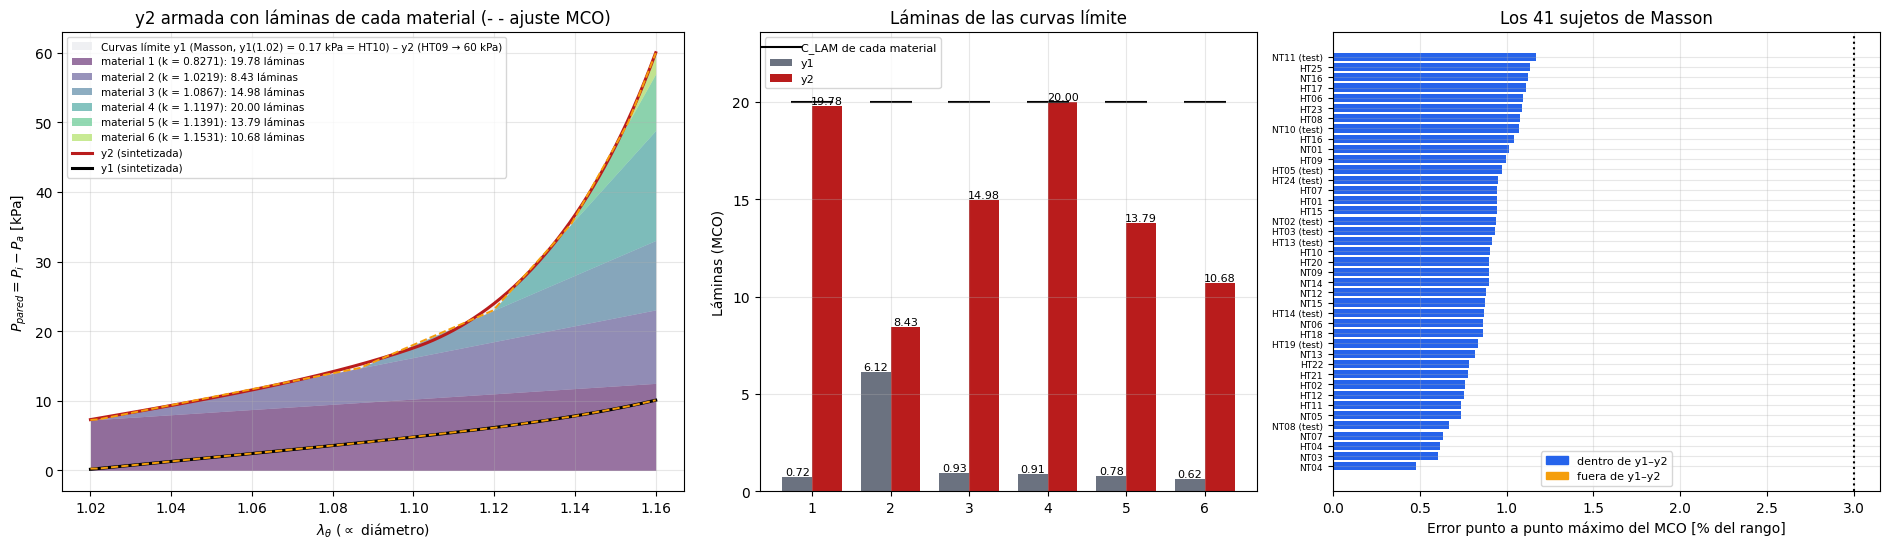

In [9]:
# CELDA 5: y2 ARMADA CON LÁMINAS, LÁMINAS DE LAS CURVAS LÍMITE Y ERROR DE LOS 41 SUJETOS
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

col = plt.cm.viridis(np.linspace(0.0, 0.85, len(NUDOS)))
fig, ax = plt.subplots(1, 3, figsize=(19, 5.6), gridspec_kw=dict(width_ratios=[1.25, 1, 1.1]))
banda(ax[0])
acum = np.cumsum(np.column_stack([np.zeros_like(X), A * C_Y2]), axis=1)
for j in range(len(NUDOS)):
    ax[0].fill_between(X, acum[:, j], acum[:, j + 1], color=col[j], alpha=0.55, lw=0,
                       label=f"material {j+1} (k = {NUDOS[j]:.4f}): {C_Y2[j]:.2f} láminas")
for y, c, cl, n in [(Y2, C_Y2, "#b91c1c", "y2 (sintetizada)"), (Y1, C_Y1, "k", "y1 (sintetizada)")]:
    ax[0].plot(X, y, color=cl, lw=2.2, label=n)
    ax[0].plot(X, A @ c, "--", color="#f59e0b", lw=1.4)
ax[0].set(xlabel=ETQ_X, ylabel=ETQ_Y, title="y2 armada con láminas de cada material (- - ajuste MCO)")
ax[0].legend(fontsize=7.5, loc="upper left")

i = np.arange(1, len(NUDOS) + 1)
for d, c, cl, n in [(-0.19, C_Y1, "#6b7280", "y1"), (0.19, C_Y2, "#b91c1c", "y2")]:
    ax[1].bar(i + d, c, 0.38, color=cl, label=n)
    for ii, v in zip(i, c):
        ax[1].text(ii + d, v, f"{v:.2f}", ha="center", va="bottom", fontsize=8)
ax[1].scatter(i, C_LAM, marker="_", s=900, color="k", label="C_LAM de cada material")
ax[1].set(xticks=i, ylabel="Láminas (MCO)", ylim=(0, 1.18 * max(C_LAM.max(), C_Y2.max())), title="Láminas de las curvas límite")
ax[1].legend(fontsize=8, loc="upper left")

d = DF_PISO.sort_values("MaxAE_rel_pct")
ax[2].barh(range(len(d)), d.MaxAE_rel_pct, color=np.where(d.en_espacio, "#2563eb", "#f59e0b"))
ax[2].set_yticks(range(len(d)), [f"{n}{' (test)' if t else ''}" for n, t in zip(d.id, d.test)], fontsize=6.5)
ax[2].axvline(ERROR_MAX_PCT, color="k", ls=":")
ax[2].set(xlabel="Error punto a punto máximo del MCO [% del rango]", title="Los 41 sujetos de Masson")
ax[2].legend(handles=[Patch(color="#2563eb", label="dentro de y1–y2"), Patch(color="#f59e0b", label="fuera de y1–y2")], fontsize=8)
for a in ax:
    a.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f"laminas_curvas_limite_{VERSION}.png", dpi=300, bbox_inches="tight")
plt.show()

## Celda 6 — Librerías, entrada logarítmica, métricas y predicción

In [10]:
# CELDA 6: LIBRERÍAS, TENSORFLOW, ENTRADA LOGARÍTMICA, MÉTRICAS, CONTROL DE CLASE Y PREDICCIÓN DE LA RED
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
import numpy as np
import tensorflow as tf
from scipy.optimize import nnls

np.random.seed(SEED)
tf.random.set_seed(SEED)
OFFSET_LOG = float(max(0.0, -min(Y1.min(), POB_Y.min())) + 5.0)   # entrada de la red: log(y + OFFSET_LOG)


def entrada_log(Y):
    return np.log(np.maximum(np.asarray(Y) + OFFSET_LOG, 1e-6))


def metricas(Y, B):
    """R², RMSE, MaxAE [kPa], NRMSE y MaxAE_rel [% del rango de cada curva]; una curva o una por fila."""
    Y, E = np.atleast_2d(Y), np.atleast_2d(Y) - np.atleast_2d(B)
    rg, rmse, maxae = np.ptp(Y, axis=1), np.sqrt(np.mean(E ** 2, axis=1)), np.abs(E).max(axis=1)
    m = dict(R2=1 - np.sum(E ** 2, axis=1) / np.sum((Y - Y.mean(axis=1, keepdims=True)) ** 2, axis=1),
             RMSE=rmse, MaxAE=maxae, NRMSE=rmse / rg * 100, MaxAE_rel=maxae / rg * 100)
    return {k: (float(v[0]) if len(v) == 1 else v) for k, v in m.items()}


def predecir(Y):
    """Láminas de cada material (diseño, C_LAM) que predice la red para una curva o una por fila."""
    c = sy.inverse_transform(model.predict(sx.transform(entrada_log(np.atleast_2d(Y))), batch_size=1024, verbose=0)) * ESC
    return c[0] if np.ndim(Y) == 1 else c


def panel(ax, s, titulo):
    """Curva de test #s: entrada, óptimo MCO y red (la usan las Celdas 13, 16 y 18)."""
    banda(ax)
    ax.plot(X, B_IN[s], "k-", lw=2, label="Curva de entrada")
    ax.plot(X, B_OPT[s], "b:", lw=1.8, label="Óptimo MCO")
    ax.plot(X, B_RN[s], "r--", lw=1.8, label="Red")
    ax.set_ylim(-0.03 * max(B_IN[s].max(), 1), 1.15 * max(B_IN[s].max(), 1))
    ax.set_title(titulo, fontsize=8.5, fontweight="bold")
    ax.set(xlabel=ETQ_X, ylabel=ETQ_Y)
    ax.grid(alpha=0.4, ls=":")
    ax.legend(fontsize=7, loc="upper left")


_K = np.linspace(NUDO_MIN_CLASE, X_MAX, N_NUDOS_CLASE + 2)[:-1]
_B_CLASE = np.maximum(0.0, X[:, None] - _K)[::3] / (X_MAX - _K)


def distancia_clase(y):
    """Distancia [% del rango] de y a las curvas realizables con capas (combinaciones c ≥ 0 de 40 líneas truncadas)."""
    ys = np.asarray(y)[::3]
    return float(np.sqrt(np.mean((ys - _B_CLASE @ nnls(_B_CLASE, ys)[0]) ** 2)) / np.ptp(y) * 100)


print(f"✅ TensorFlow {tf.__version__} ({'GPU' if tf.config.list_physical_devices('GPU') else 'CPU'}) | OFFSET_LOG = {OFFSET_LOG:g} | "
      f"control de clase: distancia ≤ {TOL_CLASE_NRMSE}%")

✅ TensorFlow 2.21.0 (CPU) | OFFSET_LOG = 5 | control de clase: distancia ≤ 2.0%


## Celda 7 — Dataset sintético (familias pura y combinada + fisiológicas)

In [11]:
# CELDA 7: DATASET SINTÉTICO (etiqueta = MCO de la misma curva que ve la red, en láminas de la red)
#   0 pura: un material, láminas log-uniformes en [0,1; C_GEN_MAX_j]   1 combinada: 2–N materiales, U(0, C_GEN_MAX_j)
#   + las familias fisiológicas de la Celda 2
import numpy as np
import pandas as pd

C_MIN_PURA, RUIDO_PURAS = 0.10, 0.005
rng_b = np.random.default_rng(2028)
nb = len(NUDOS)
c0 = np.zeros((N_FAM[0], nb))
j0 = rng_b.permutation(np.arange(N_FAM[0]) % nb)
c0[np.arange(N_FAM[0]), j0] = np.exp(rng_b.uniform(np.log(C_MIN_PURA), np.log(C_GEN_MAX[j0])))
c1 = np.zeros((N_FAM[1], nb))
for i in range(N_FAM[1]):
    act = rng_b.choice(nb, size=rng_b.integers(2, nb + 1), replace=False)
    c1[i, act] = rng_b.uniform(0.0, 1.0, size=len(act)) * C_GEN_MAX[act]
c1 *= np.minimum(1.0, Y_TECHO / np.maximum((c1 @ A_RED.T).max(axis=1, keepdims=True), 1e-9))
for f, c in ((0, c0), (1, c1)):
    LIMPIAS[f] = c @ A_RED.T
    RUIDOSAS[f] = ruido(LIMPIAS[f], RUIDO_PURAS, rng_b)

Y_limpio, Y_raw = (np.vstack([D[f] for f in sorted(FAMILIAS)]) for D in (LIMPIAS, RUIDOSAS))
familia = np.concatenate([np.full(N_FAM[f], f, np.int8) for f in sorted(FAMILIAS)])
C_RED = mco(Y_raw, A_RED)                                           # etiquetas (láminas de la red)
MASCARA = np.zeros_like(C_RED, dtype=np.float32)                    # crosstalk: materiales que el generador dejó en 0
MASCARA[:N_FAM[0] + N_FAM[1]] = np.vstack([c0, c1]) == 0
X_log = entrada_log(Y_raw)

_C0 = mco(Y_limpio, A)
_eM = err_pct(Y_limpio, _C0 @ A.T)[0]
print(f"✅ Dataset: {N_SAMPLES} curvas | etiquetas MCO en láminas")
print(pd.DataFrame({FAMILIAS[f]: {"curvas": N_FAM[f], "puntos fuera de y1–y2 %": 100 * np.mean((Y_raw[m] < Y1) | (Y_raw[m] > Y2)),
                                  "aceptación %": 100 * ACEPTACION.get(f, 1.0), f"MCO cumple ≤{ERROR_MAX_PCT:g}% %": 100 * np.mean(_eM[m] <= ERROR_MAX_PCT),
                                  "error MCO máx. %": _eM[m].max(), "fabricables %": 100 * np.mean((C_RED[m] >= -1e-9).all(1))}
                    for f in FAMILIAS for m in [familia == f]}).T.round(2).to_string())
_esp = np.isin(familia, (2, 3, 5))
print(f"Espacio de trabajo ({_esp.sum()} curvas de Masson dentro de y1–y2): máximo de láminas por material "
      f"{_C0[_esp].max(0).round(2)} (C_LAM = {C_LAM})")

✅ Dataset: 50000 curvas | etiquetas MCO en láminas
                        curvas  puntos fuera de y1–y2 %  aceptación %  MCO cumple ≤3% %  error MCO máx. %  fabricables %
pura                   10000.0                    92.18        100.00             100.0              0.00           0.03
combinada              10000.0                    30.85        100.00             100.0              0.00          36.14
constitutiva           10000.0                     0.02         95.52             100.0              1.20         100.00
constitutiva_amplia     7500.0                     0.03         80.39             100.0              1.32         100.00
exponencial             5000.0                     3.89         99.52             100.0              2.24          99.94
constitutiva_uniforme   5000.0                     0.02         87.47             100.0              1.38         100.00
pacientes               2500.0                     0.99        100.00             100.0              1

## Celda 8 — Partición y normalización

In [12]:
# CELDA 8: PARTICIÓN TRAIN / VAL / TEST (estratificada por familia) Y NORMALIZACIÓN
# Con ENTRENAR = False se usan los escaladores guardados con la red; deben coincidir con los de este dataset.
import pickle
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

idx_trval, idx_test = train_test_split(np.arange(N_SAMPLES), test_size=0.20, random_state=SEED, stratify=familia)
idx_train, idx_val = train_test_split(idx_trval, test_size=0.125, random_state=SEED, stratify=familia[idx_trval])
sx, sy = StandardScaler().fit(X_log[idx_train]), StandardScaler().fit(C_RED[idx_train])
if not ENTRENAR:
    with open(ARCHIVO_SCALERS, "rb") as f:
        meta = pickle.load(f)
    dif = max(np.abs(meta["scaler_x"].mean_ - sx.mean_).max(), np.abs(meta["scaler_y"].mean_ - sy.mean_).max())
    sx, sy = meta["scaler_x"], meta["scaler_y"]
    assert meta["offset_log"] == OFFSET_LOG, "OFFSET_LOG distinto del de la red guardada"
    assert np.allclose(meta["nudos"], NUDOS), f"la red se entrenó con los nudos {np.round(meta['nudos'], 4).tolist()}"
    print(f"📦 Escaladores de '{ARCHIVO_SCALERS}' | diferencia con este dataset: {dif:.1e} (≈ 0 ⇒ mismo dataset de entrenamiento)")
X_train, X_val, X_test = (sx.transform(X_log[i]) for i in (idx_train, idx_val, idx_test))
y_train, y_val, y_test = (sy.transform(C_RED[i]) for i in (idx_train, idx_val, idx_test))
m_train, m_val = MASCARA[idx_train], MASCARA[idx_val]
print(f"✅ Train {len(idx_train)} | Val {len(idx_val)} | Test {len(idx_test)} | sy.mean_ {sy.mean_.round(4)} | "
      f"sy.scale_ {sy.scale_.round(4)} | crosstalk penalizado en {MASCARA.mean():.1%} de los coeficientes")

/usr/local/lib/python3.13/dist-packages/sklearn/base.py:380: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.7.0 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


📦 Escaladores de 'scalers_curva_j_v28_6.pkl' | diferencia con este dataset: 3.4e-11 (≈ 0 ⇒ mismo dataset de entrenamiento)
✅ Train 35000 | Val 5000 | Test 10000 | sy.mean_ [3.5259 2.8802 2.6656 2.3976 2.4349 2.2015] | sy.scale_ [2.8007 2.3264 2.4537 2.2971 2.3519 2.2587] | crosstalk penalizado en 23.2% de los coeficientes


## Celda 9 — Pérdida y arquitectura

In [13]:
# CELDA 9: PÉRDIDA Y ARQUITECTURA
# L = 1·MSE(láminas estandarizadas) + 5·MSE(A·ĉ − A·c, relativo al máximo de cada curva) + PESO_CROSSTALK·media(ĉ² en materiales ausentes)
import numpy as np
import tensorflow as tf

PESO_COEF, PESO_REC, PESO_CROSSTALK = 1.0, 5.0, 5.0      # 5 con C_LAM_RED = 10 (peso efectivo ≈ 14, la mejor red: V22)
CAPAS_OCULTAS, L2 = (256, 128, 64), 1e-5
nb = len(NUDOS)
_A_tf, _mu, _sd = (tf.constant(v, tf.float32) for v in (A_RED.T, sy.mean_, sy.scale_))


def perdida(y_aug, y_pred):
    y_true, mascara = y_aug[:, :nb], y_aug[:, nb:]                  # etiqueta | máscara de crosstalk
    c_true, c_pred = y_true * _sd + _mu, y_pred * _sd + _mu
    b_true, b_pred = c_true @ _A_tf, c_pred @ _A_tf
    y_max = tf.maximum(tf.reduce_max(b_true, axis=1, keepdims=True), 1.0)
    return (PESO_COEF * tf.reduce_mean(tf.square(y_true - y_pred))
            + PESO_REC * tf.reduce_mean(tf.square((b_true - b_pred) / (y_max + 1e-6)))
            + PESO_CROSSTALK * tf.reduce_mean(tf.square(c_pred) * mascara))


def mae(y_aug, y_pred):
    return tf.reduce_mean(tf.abs(y_aug[:, :nb] - y_pred))


capas = [tf.keras.Input(shape=(N_PTS,))]
for u in CAPAS_OCULTAS:
    capas += [tf.keras.layers.Dense(u, activation="relu", kernel_regularizer=tf.keras.regularizers.l2(L2)),
              tf.keras.layers.LayerNormalization()]
model = tf.keras.Sequential(capas + [tf.keras.layers.Dense(nb)])
model.compile(optimizer=tf.keras.optimizers.Adam(1e-3, clipnorm=1.0), loss=perdida, metrics=[mae])
print(f"✅ Red {N_PTS} → {' → '.join(map(str, CAPAS_OCULTAS))} → {nb} (ReLU + LayerNormalization) | "
      f"{model.count_params():,} parámetros | pesos de la pérdida: {PESO_COEF:g} / {PESO_REC:g} / {PESO_CROSSTALK:g}")

✅ Red 999 → 256 → 128 → 64 → 6 (ReLU + LayerNormalization) | 298,438 parámetros | pesos de la pérdida: 1 / 5 / 5


## Celda 10 — Integridad de los datos

In [14]:
# CELDA 10: INTEGRIDAD DE LOS DATOS
import numpy as np

for k, v in dict(X_train=X_train, y_train=y_train, X_val=X_val, y_val=y_val, X_test=X_test, y_test=y_test).items():
    assert np.isfinite(v).all(), f"{k} tiene NaN o Inf"
print(f"✅ Sin NaN ni Inf | etiquetas en [{C_RED.min():.3f}, {C_RED.max():.3f}] láminas | "
      f"curvas con algún c < 0: {np.mean(C_RED.min(1) < 0):.1%}")

✅ Sin NaN ni Inf | etiquetas en [-0.726, 21.511] láminas | curvas con algún c < 0: 32.8%


## Celda 11 — Entrenamiento o carga de la red

📦 Red cargada de 'modelo_rn_curva_j_v28_6.keras' (sin reentrenar; 2721 épocas de entrenamiento)
   Pesos de la época 2641: val_loss 0.001423 | loss 0.001374 | convergencia práctica (≤ 1 % del mínimo) en la época 2625


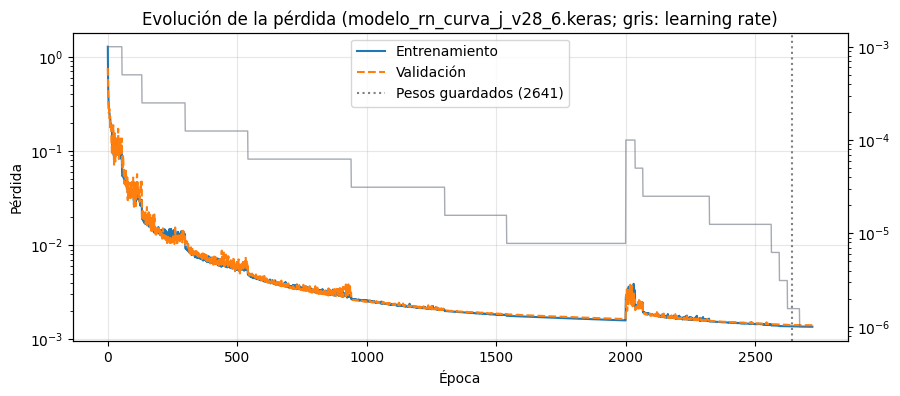

In [15]:
# CELDA 11: ENTRENAMIENTO (ENTRENAR = True) O CARGA DE LA RED ENTRENADA (False)
#   CONTINUAR = True (con la red cargada): sigue entrenando desde sus pesos con la tasa de aprendizaje reiniciada en LR_REINICIO;
#   solo guarda si baja la pérdida de validación. Poner de nuevo en False después de usarlo.
import time
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow.keras import callbacks as cb
from tensorflow.keras.models import load_model

EPOCHS, BATCH_SIZE, MIN_DELTA = 2000, 64, 1e-5
CONTINUAR, EPOCAS_EXTRA, LR_REINICIO = False, 2000, 1e-4


def _callbacks():
    return [cb.TerminateOnNaN(), cb.EarlyStopping(patience=80, min_delta=MIN_DELTA, restore_best_weights=True),
            cb.ReduceLROnPlateau(factor=0.5, patience=30, min_delta=MIN_DELTA, min_lr=1e-6)]


if ENTRENAR:
    t0 = time.time()
    h = model.fit(X_train, np.hstack([y_train, m_train]), validation_data=(X_val, np.hstack([y_val, m_val])),
                  epochs=EPOCHS, batch_size=BATCH_SIZE, verbose=2,
                  callbacks=_callbacks())
    hist = pd.DataFrame(h.history, index=pd.RangeIndex(1, len(h.history["loss"]) + 1, name="epoca"))
    model.save(ARCHIVO_MODELO)
    with open(ARCHIVO_SCALERS, "wb") as f:
        pickle.dump(dict(scaler_x=sx, scaler_y=sy, offset_log=OFFSET_LOG, c_lam_red=C_LAM_RED, nudos=NUDOS, version=VERSION), f)
    hist.to_csv(ARCHIVO_HISTORIAL)
    print(f"✅ Entrenada en {(time.time() - t0) / 60:.1f} min ({len(hist)} épocas) → {ARCHIVO_MODELO}, {ARCHIVO_SCALERS}")
else:
    model = load_model(ARCHIVO_MODELO, compile=False)
    hist = pd.read_csv(ARCHIVO_HISTORIAL, index_col="epoca")
    print(f"📦 Red cargada de '{ARCHIVO_MODELO}' (sin reentrenar; {len(hist)} épocas de entrenamiento)")
    if CONTINUAR:
        import tensorflow as tf
        Yv = np.hstack([y_val, m_val])
        model.compile(optimizer=tf.keras.optimizers.Adam(LR_REINICIO, clipnorm=1.0), loss=perdida, metrics=[mae])
        v0, n0, t0 = model.evaluate(X_val, Yv, batch_size=1024, verbose=0)[0], len(hist), time.time()
        h = model.fit(X_train, np.hstack([y_train, m_train]), validation_data=(X_val, Yv), initial_epoch=n0,
                      epochs=n0 + EPOCAS_EXTRA, batch_size=BATCH_SIZE, verbose=2, callbacks=_callbacks())
        v1 = model.evaluate(X_val, Yv, batch_size=1024, verbose=0)[0]
        print(f"   Continuación: val_loss {v0:.6f} → {v1:.6f} ({(v1 / v0 - 1) * 100:+.1f} %), {len(h.history['loss'])} épocas en "
              f"{(time.time() - t0) / 60:.1f} min")
        if v1 < v0:
            hist = pd.concat([hist, pd.DataFrame(h.history, index=pd.RangeIndex(n0 + 1, n0 + len(h.history["loss"]) + 1, name="epoca"))])
            model.save(ARCHIVO_MODELO)
            hist.to_csv(ARCHIVO_HISTORIAL)
            print(f"   ✅ Mejoró: guardada en {ARCHIVO_MODELO} ({len(hist)} épocas en total)")
        else:
            model = load_model(ARCHIVO_MODELO, compile=False)
            print("   ↩️ No mejoró: se mantiene la red anterior")

v = hist["val_loss"].to_numpy()
mejor, ep = np.inf, len(v)                       # época que restaura EarlyStopping (última mejora > MIN_DELTA)
for i, x_ in enumerate(v):
    if x_ + MIN_DELTA < mejor:
        mejor, ep = x_, i + 1
ep_conv = int(np.argmax(v <= v.min() * 1.01)) + 1
print(f"   Pesos de la época {ep}: val_loss {v[ep - 1]:.6f} | loss {hist['loss'].iloc[ep - 1]:.6f} | "
      f"convergencia práctica (≤ 1 % del mínimo) en la época {ep_conv}")
fig, ax = plt.subplots(figsize=(10, 4))
ax.semilogy(hist.index, hist["loss"], label="Entrenamiento")
ax.semilogy(hist.index, v, "--", label="Validación")
ax.axvline(ep, color="gray", ls=":", label=f"Pesos guardados ({ep})")
lr = next((c for c in ("learning_rate", "lr") if c in hist), None)
if lr:
    ax.twinx().semilogy(hist.index, hist[lr], color="#6b7280", lw=1, alpha=0.6)
ax.set(xlabel="Época", ylabel="Pérdida", title=f"Evolución de la pérdida ({ARCHIVO_MODELO}; gris: learning rate)")
ax.legend()
ax.grid(alpha=0.3)
plt.savefig(f"evolucion_perdida_{VERSION}.png", dpi=300, bbox_inches="tight")
plt.show()

## Celda 12 — Evaluación base en test

In [16]:
# CELDA 12: EVALUACIÓN BASE EN TEST (la usan las Celdas 13, 16 y 18)
# Todo en láminas del diseño (C_LAM). La red se evalúa sin pulido; el pulido en MCO es c = A⁺y (ecuaciones normales).
import time
import numpy as np

t0 = time.perf_counter()
C_RN = predecir(Y_raw[idx_test])
t_rn = (time.perf_counter() - t0) / len(idx_test)
C_OPT = C_RED[idx_test] * ESC                                     # etiqueta = MCO de la curva de entrada
FAM_T, B_IN, B_LIMPIO = familia[idx_test], Y_raw[idx_test], Y_limpio[idx_test]
B_RN, B_OPT = C_RN @ A.T, C_OPT @ A.T
t0 = time.perf_counter()
for y in B_IN[:300]:
    np.linalg.lstsq(A, y, rcond=None)
t_mco = (time.perf_counter() - t0) / 300
g = np.abs((A.T @ (B_OPT - B_IN).T)).max(0) / np.abs(A.T @ B_IN.T).max(0)
print(f"✅ Test: {len(idx_test)} curvas | láminas negativas: red {np.mean(C_RN.min(1) < 0):.1%} de las curvas "
      f"(mín. {C_RN.min():.3f}), MCO {np.mean(C_OPT.min(1) < 0):.1%} (mín. {C_OPT.min():.3f})")
print(f"   Pulido (MCO): ecuaciones normales |Aᵀ(Ac − y)| / |Aᵀy| ≤ {g.max():.1e} ⇒ red + pulido = óptimo exacto")
print(f"   Tiempo por curva: red en lote {t_rn * 1e3:.4f} ms | MCO {t_mco * 1e3:.4f} ms")

✅ Test: 10000 curvas | láminas negativas: red 30.6% de las curvas (mín. -0.040), MCO 32.9% (mín. -0.701)
   Pulido (MCO): ecuaciones normales |Aᵀ(Ac − y)| / |Aᵀy| ≤ 1.9e-15 ⇒ red + pulido = óptimo exacto
   Tiempo por curva: red en lote 0.1025 ms | MCO 0.1381 ms


## Celda 13 — Reconstrucción en test (una muestra por familia)

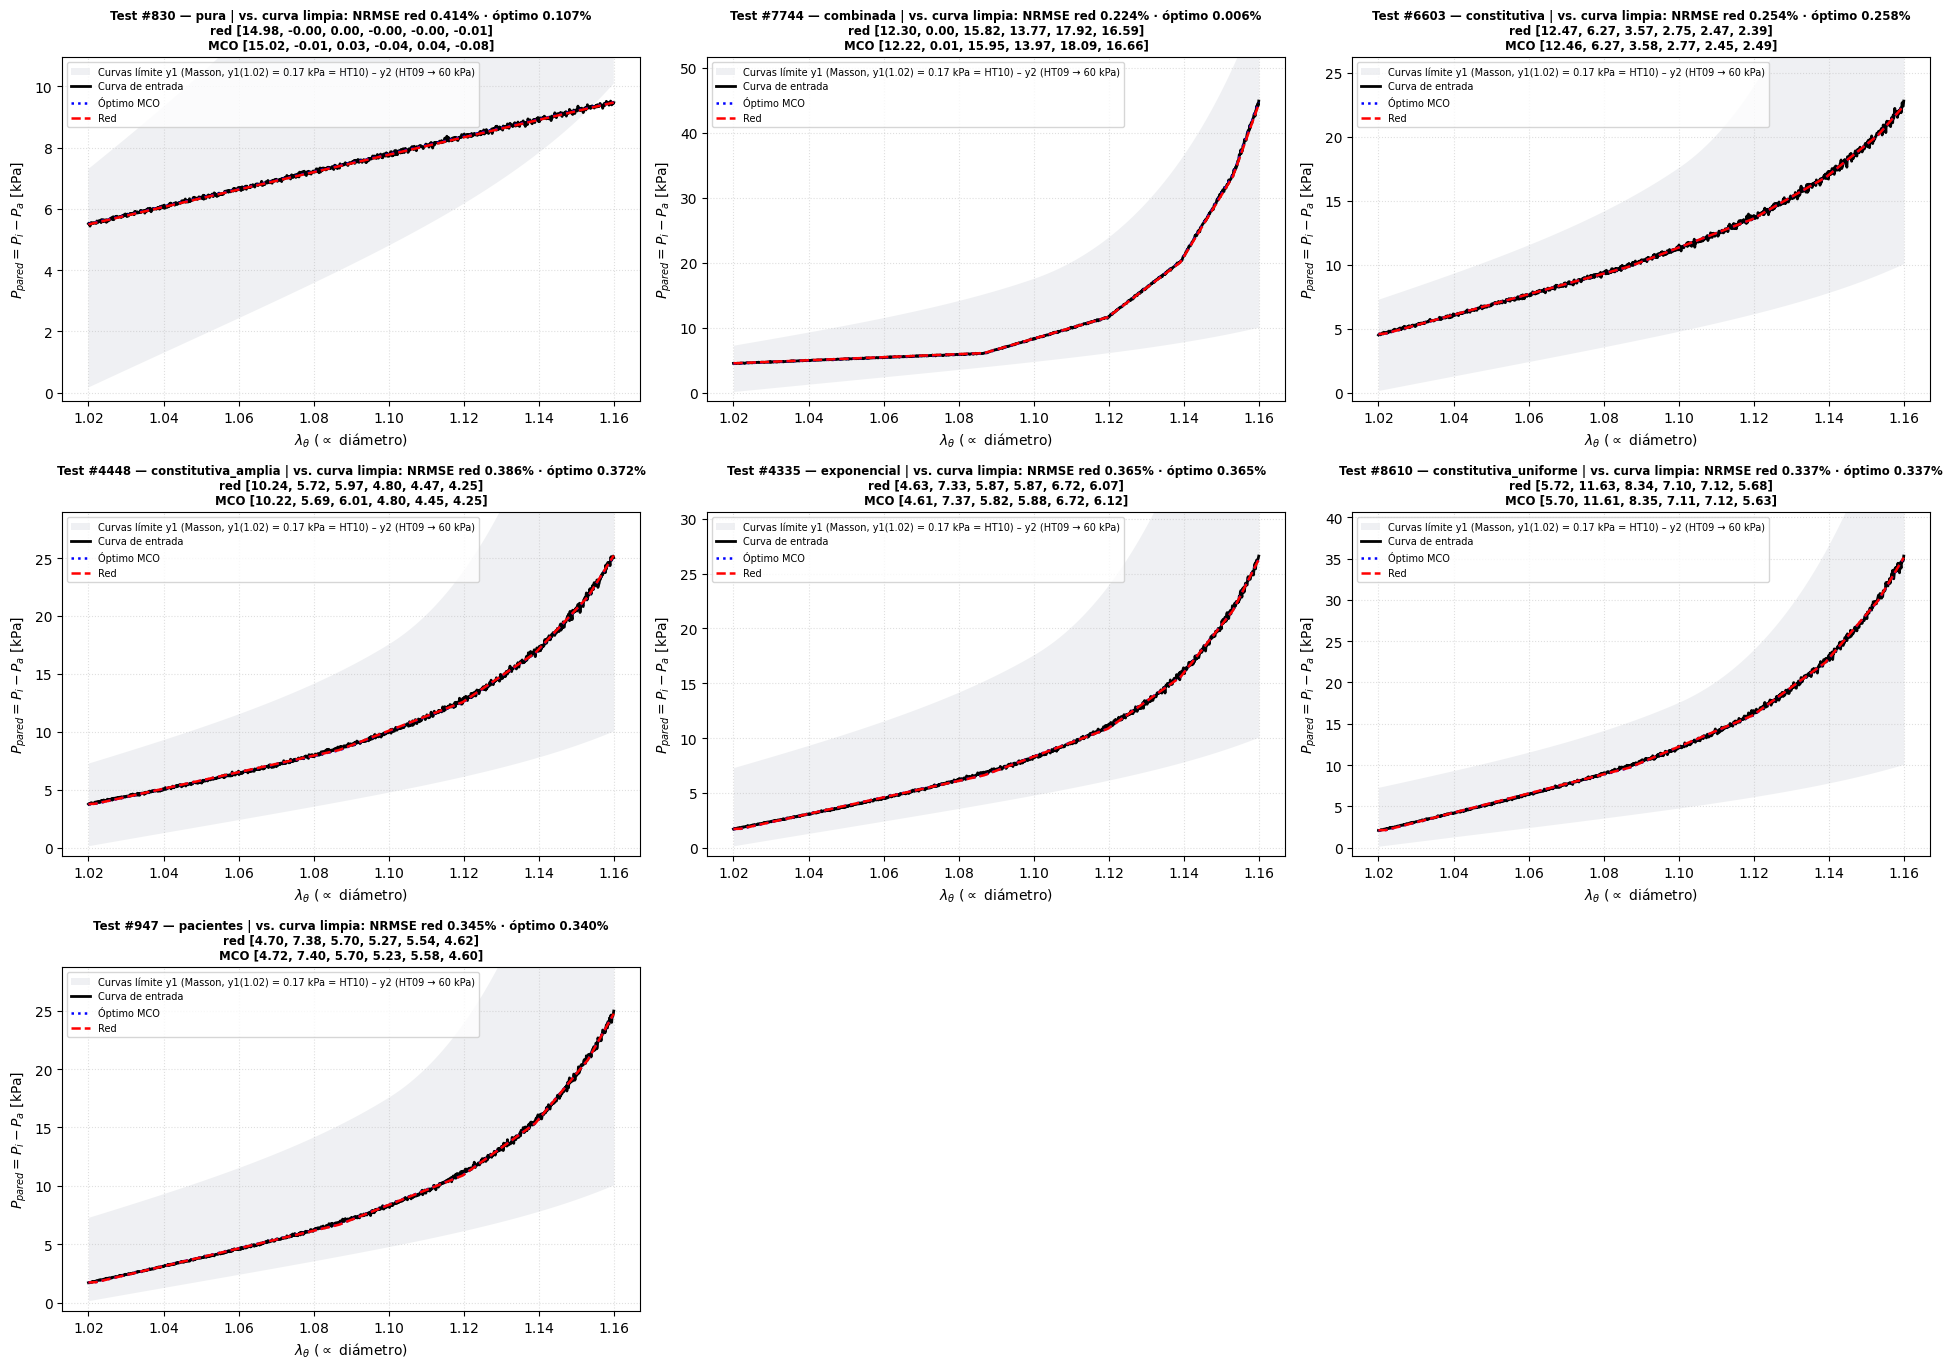

NRMSE medio [%] por familia:
                       red vs. limpia  óptimo vs. limpia  red vs. entrada con ruido
pura                            0.205              0.029                      0.398
combinada                       0.267              0.024                      0.383
constitutiva                    0.353              0.334                      0.651
constitutiva_amplia             0.358              0.333                      0.657
exponencial                     0.400              0.366                      0.663
constitutiva_uniforme           0.355              0.328                      0.680
pacientes                       0.351              0.334                      0.651


In [17]:
# CELDA 13: RECONSTRUCCIÓN EN TEST (una muestra por familia) Y ERROR CONTRA LA CURVA SIN RUIDO
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


rng_plot = np.random.default_rng(SEED)
fig, axes = plt.subplots(3, 3, figsize=(19.5, 13.8))
for ax, f in zip(axes.flat, sorted(FAMILIAS)):
    s = int(rng_plot.choice(np.where(FAM_T == f)[0]))
    mr, mo = metricas(B_LIMPIO[s], B_RN[s]), metricas(B_LIMPIO[s], B_OPT[s])
    panel(ax, s, f"Test #{s} — {FAMILIAS[f]} | vs. curva limpia: NRMSE red {mr['NRMSE']:.3f}% · óptimo {mo['NRMSE']:.3f}%\n"
                 f"red [{', '.join(f'{v:.2f}' for v in C_RN[s])}]\nMCO [{', '.join(f'{v:.2f}' for v in C_OPT[s])}]")
for ax in axes.flat[len(FAMILIAS):]:
    ax.axis("off")
plt.tight_layout()
plt.savefig(f"reconstruccion_curvas_test_{VERSION}.png", dpi=300, bbox_inches="tight")
plt.show()

M0_RN, M0_OPT, MI_RN = metricas(B_LIMPIO, B_RN), metricas(B_LIMPIO, B_OPT), metricas(B_IN, B_RN)
print("NRMSE medio [%] por familia:")
print(pd.DataFrame({FAMILIAS[f]: {"red vs. limpia": M0_RN["NRMSE"][m].mean(), "óptimo vs. limpia": M0_OPT["NRMSE"][m].mean(),
                                  "red vs. entrada con ruido": MI_RN["NRMSE"][m].mean()}
                    for f in FAMILIAS for m in [FAM_T == f]}).T.round(3).to_string())

## Celda 14 — Validación con los 41 sujetos y las 4 curvas medias

In [18]:
# CELDA 14: VALIDACIÓN CON LOS 41 SUJETOS REALES Y LAS 4 CURVAS MEDIAS (red vs. óptimo MCO, sin ruido)
import numpy as np
import pandas as pd

C_SUJ_RN, C_SUJ_OPT = predecir(POB_Y), mco(POB_Y)
MS_RN, MS_OPT = metricas(POB_Y, C_SUJ_RN @ A.T), metricas(POB_Y, C_SUJ_OPT @ A.T)
DF_SUJ = POB[["id", "grupo", "test"]].assign(R2_red=MS_RN["R2"], R2_opt=MS_OPT["R2"], NRMSE_red=MS_RN["NRMSE"],
                                             NRMSE_opt=MS_OPT["NRMSE"], MaxAE_rel_red=MS_RN["MaxAE_rel"],
                                             dc_max=np.abs(C_SUJ_RN - C_SUJ_OPT).max(1),
                                             en_clase=[distancia_clase(y) <= TOL_CLASE_NRMSE for y in POB_Y])
DF_SUJ["exceso_pct"] = (DF_SUJ.NRMSE_red / DF_SUJ.NRMSE_opt - 1) * 100
DF_SUJ.to_csv(f"validacion_sujetos_reales_{VERSION}.csv", index=False)
print(pd.DataFrame({k: {"n": m.sum(), "R² red mín.": DF_SUJ.R2_red[m].min(), "NRMSE óptimo %": DF_SUJ.NRMSE_opt[m].mean(),
                        "NRMSE red %": DF_SUJ.NRMSE_red[m].mean(),
                        "exceso %": (DF_SUJ.NRMSE_red[m].mean() / DF_SUJ.NRMSE_opt[m].mean() - 1) * 100,
                        "error pto. red máx. %": DF_SUJ.MaxAE_rel_red[m].max(),
                        f"red cumple ≤{ERROR_MAX_PCT:g}%": (DF_SUJ.MaxAE_rel_red[m] <= ERROR_MAX_PCT).sum(), "máx |Δc|": DF_SUJ.dc_max[m].max()}
                    for k, m in {"Test": DF_SUJ.test, "Entrenamiento": ~DF_SUJ.test, "NT": DF_SUJ.grupo == "NT",
                                 "HT": DF_SUJ.grupo == "HT", "Todos": DF_SUJ.id.notna()}.items()}).T.round(4).to_string())
_t = DF_SUJ[DF_SUJ.test]
print(f"Peor R² de la red: {DF_SUJ.id[DF_SUJ.R2_red.idxmin()]} | exceso en test: mediana {_t.exceso_pct.median():+.1f}%, "
      f"máximo {_t.exceso_pct.max():+.1f}% ({_t.id[_t.exceso_pct.idxmax()]}) | control de clase: {DF_SUJ.en_clase.mean():.0%} aceptados")

RES_MEDIAS = {}
for k, y in MEDIAS.items():
    c_rn, c_opt = predecir(y), mco(y)
    RES_MEDIAS[k] = dict(y=y, b_rn=A @ c_rn, b_opt=A @ c_opt, m_rn=metricas(y, A @ c_rn), m_opt=metricas(y, A @ c_opt))
    print(f"\n{k} (n = {GRUPOS_MEDIAS[k].sum()}): láminas MCO {c_opt.round(4)} (total {c_opt.sum():.2f}) | red {c_rn.round(4)}")
    print(f"   NRMSE red {RES_MEDIAS[k]['m_rn']['NRMSE']:.4f}% / óptimo {RES_MEDIAS[k]['m_opt']['NRMSE']:.4f}% | "
          f"error pto. red {RES_MEDIAS[k]['m_rn']['MaxAE_rel']:.3f}% / óptimo {RES_MEDIAS[k]['m_opt']['MaxAE_rel']:.3f}% | "
          f"exceso de RMSE {(RES_MEDIAS[k]['m_rn']['RMSE'] / RES_MEDIAS[k]['m_opt']['RMSE'] - 1) * 100:+.2f}%")

                  n  R² red mín.  NRMSE óptimo %  NRMSE red %  exceso %  error pto. red máx. %  red cumple ≤3%  máx |Δc|
Test           10.0       0.9997          0.3538       0.3917   10.7305                 1.1476            10.0    0.0953
Entrenamiento  31.0       0.9997          0.3275       0.3363    2.6969                 1.1317            31.0    0.0890
NT             16.0       0.9997          0.3133       0.3372    7.6459                 1.1476            16.0    0.0953
HT             25.0       0.9997          0.3471       0.3579    3.1135                 1.1317            25.0    0.0890
Todos          41.0       0.9997          0.3339       0.3498    4.7729                 1.1476            41.0    0.0953
Peor R² de la red: NT11 | exceso en test: mediana +3.9%, máximo +95.8% (NT08) | control de clase: 100% aceptados

Mean Young (n = 7): láminas MCO [11.6964  4.9714  3.2204  2.9575  2.9921  2.5788] (total 28.42) | red [11.7176  4.9533  3.2182  2.9502  2.9963  2.5965]
   NRMSE

## Celda 15 — Figuras: curvas medias y sujetos de test

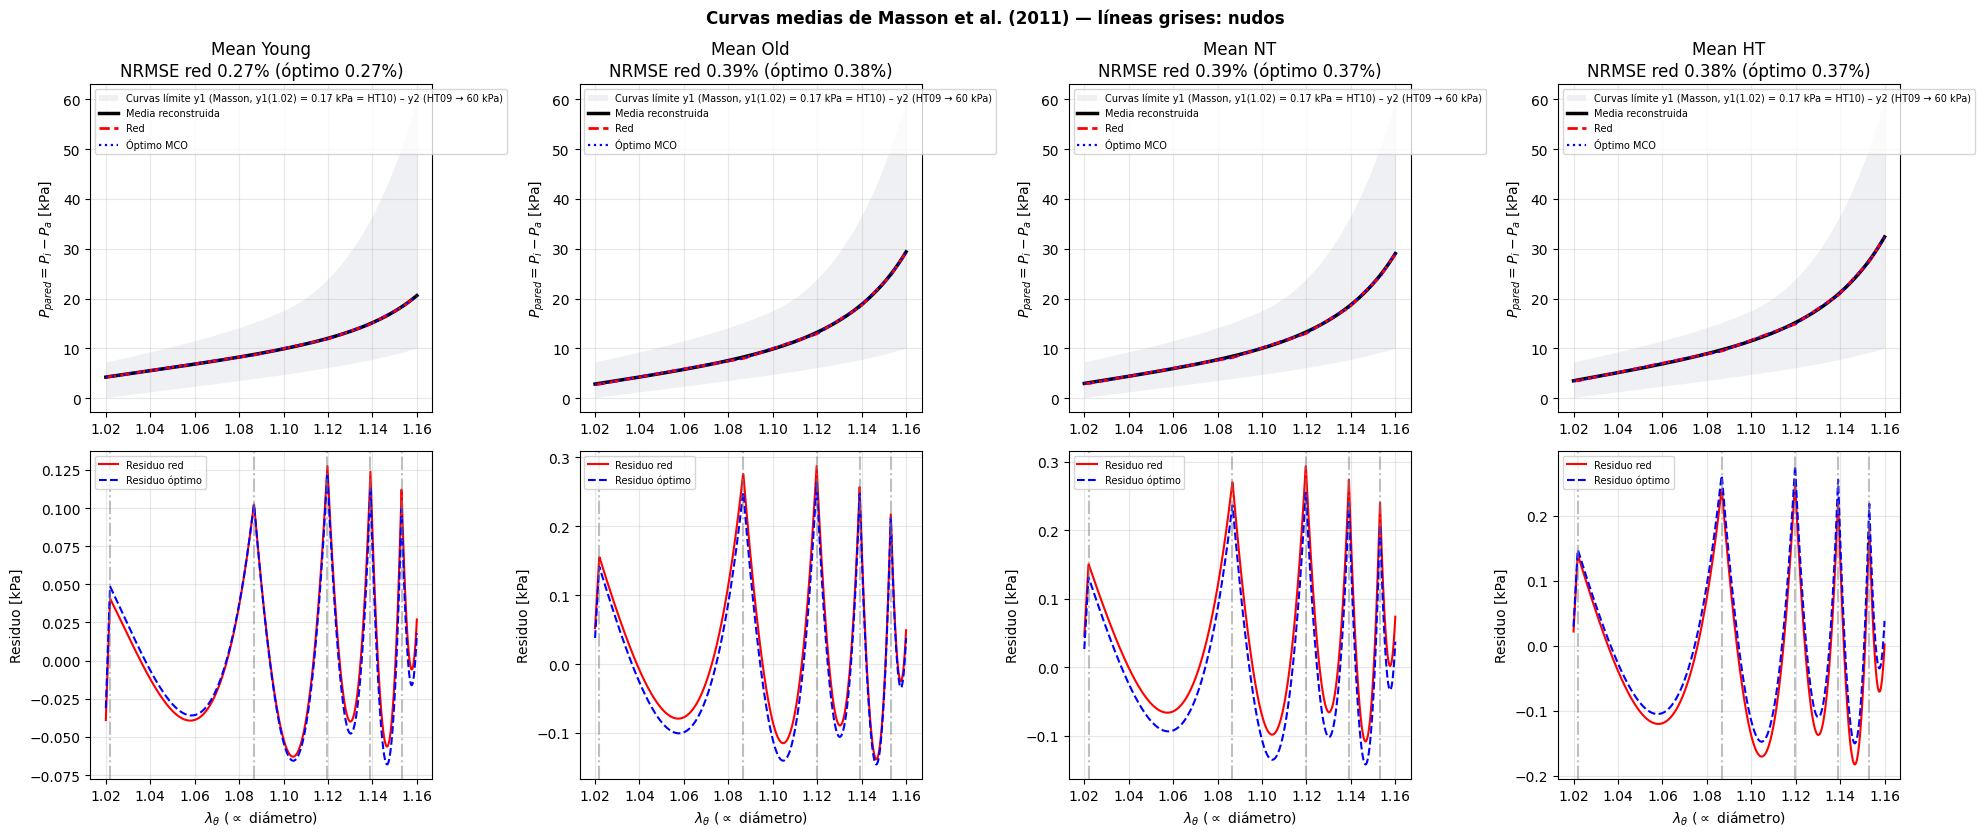

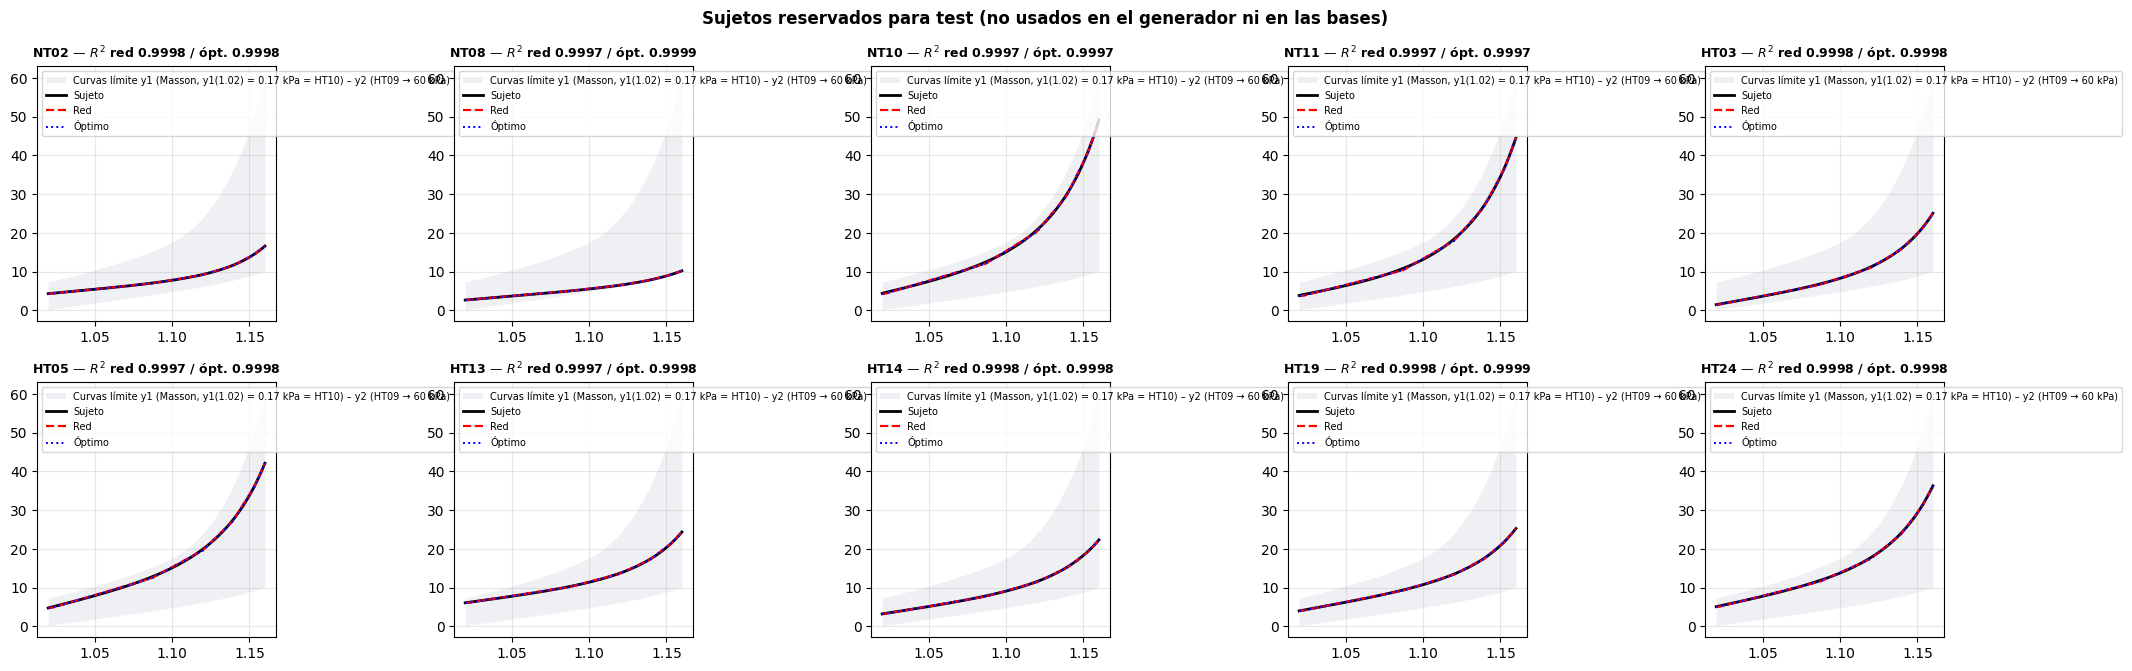

In [19]:
# CELDA 15: FIGURAS DE VALIDACIÓN — CURVAS MEDIAS (con residuos) Y SUJETOS DE TEST
import numpy as np
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 4, figsize=(20, 8.5))
for (k, r), a, b in zip(RES_MEDIAS.items(), axes[0], axes[1]):
    banda(a)
    a.plot(X, r["y"], "k-", lw=2.5, label="Media reconstruida")
    a.plot(X, r["b_rn"], "r--", lw=2, label="Red")
    a.plot(X, r["b_opt"], "b:", lw=1.6, label="Óptimo MCO")
    a.set(title=f"{k}\nNRMSE red {r['m_rn']['NRMSE']:.2f}% (óptimo {r['m_opt']['NRMSE']:.2f}%)", ylabel=ETQ_Y)
    a.legend(fontsize=7, loc="upper left")
    b.plot(X, r["y"] - r["b_rn"], "r-", lw=1.5, label="Residuo red")
    b.plot(X, r["y"] - r["b_opt"], "b--", lw=1.5, label="Residuo óptimo")
    for k_ in NUDOS[NUDOS >= X_MIN]:
        b.axvline(k_, color="gray", ls="-.", alpha=0.5)
    b.set(xlabel=ETQ_X, ylabel="Residuo [kPa]")
    b.legend(fontsize=7)
for a in axes.flat:
    a.grid(alpha=0.3)
plt.suptitle("Curvas medias de Masson et al. (2011) — líneas grises: nudos", fontweight="bold")
plt.tight_layout()
plt.savefig(f"validacion_curvas_medias_{VERSION}.png", dpi=300, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(2, 5, figsize=(21, 6.8))
for ax, i in zip(axes.flat, np.where(MASK_TEST)[0]):
    banda(ax)
    ax.plot(X, POB_Y[i], "k-", lw=2, label="Sujeto")
    ax.plot(X, A @ C_SUJ_RN[i], "r--", lw=1.6, label="Red")
    ax.plot(X, A @ C_SUJ_OPT[i], "b:", lw=1.4, label="Óptimo")
    ax.set_title(f"{POB.id[i]} — $R^2$ red {MS_RN['R2'][i]:.4f} / ópt. {MS_OPT['R2'][i]:.4f}", fontsize=9, fontweight="bold")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=7, loc="upper left")
plt.suptitle("Sujetos reservados para test (no usados en el generador ni en las bases)", fontweight="bold")
plt.tight_layout()
plt.savefig(f"validacion_sujetos_test_{VERSION}.png", dpi=300, bbox_inches="tight")
plt.show()

## Celda 16 — Evaluación en test por familia, criterio y peores casos

Láminas, todas las familias (n = 10000): R² [0.999937 0.999932 0.999901 0.999804 0.999787 0.999477] | MAE [0.0265 0.0219 0.027  0.0311 0.0375 0.0589]
Láminas, familias fisiológicas (n = 6000): R² [0.999911 0.999884 0.999896 0.999848 0.999714 0.999325] | MAE [0.0282 0.0215 0.0242 0.026  0.032  0.0474]

Reconstrucción contra la curva de entrada; criterio contra la curva sin ruido. Exceso = NRMSE red / NRMSE óptimo − 1.
                            n  NRMSE óptimo %  NRMSE red %  exceso %  R² red mín.  peor (test #)  red cumple ≤3% %  red máx. %  MCO cumple ≤3% %  MCO máx. %
pura                   2000.0           0.293        0.398    35.763        0.983         5655.0            98.350       9.620             100.0       0.882
combinada              2000.0           0.235        0.383    63.263        0.554         1532.0            98.800      22.483             100.0       0.586
constitutiva           2000.0           0.642        0.651     1.454        0.997         8060.0           1

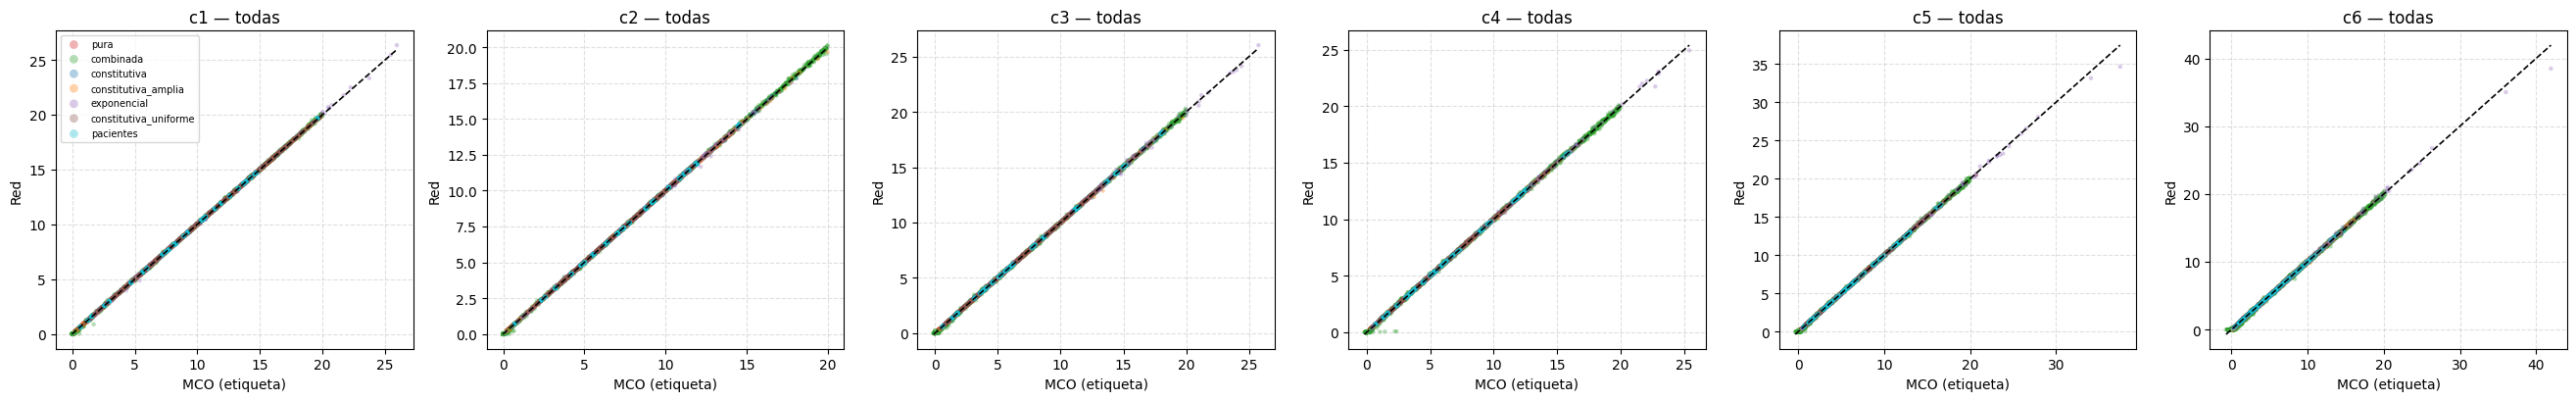

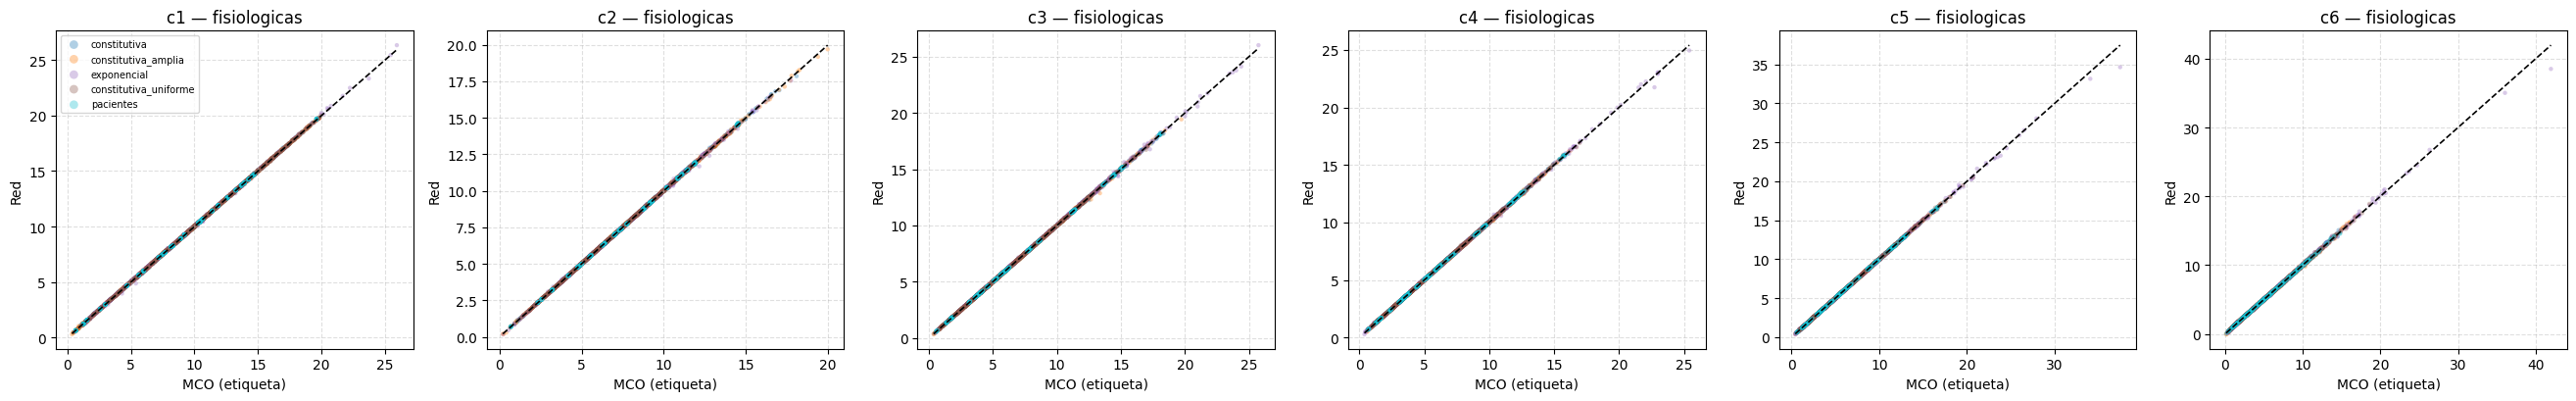

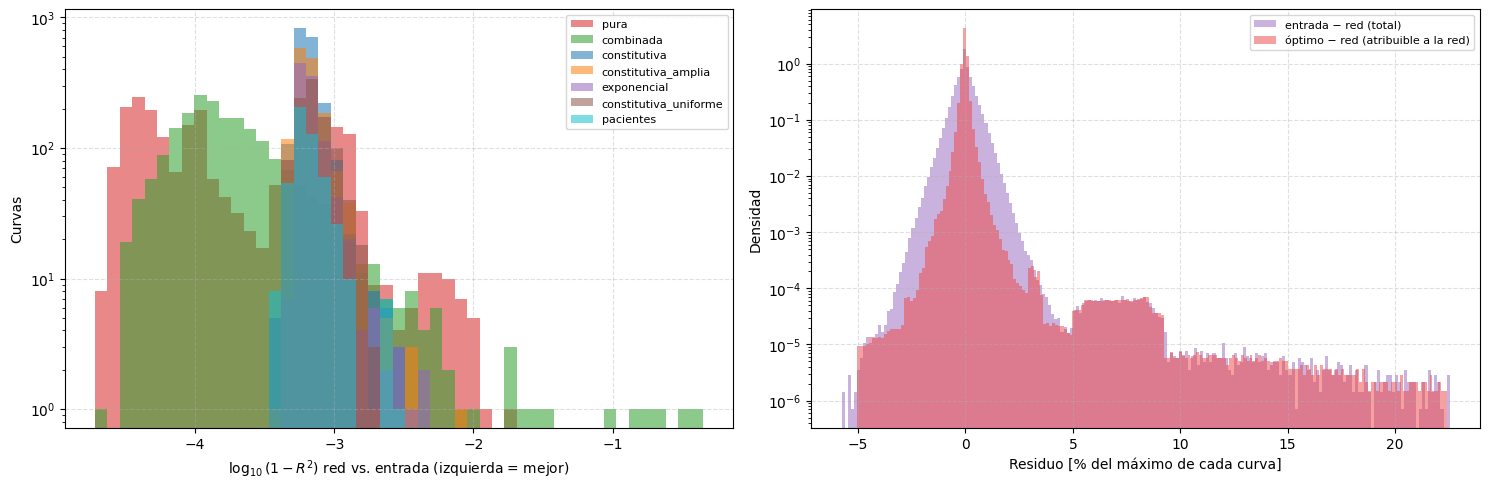

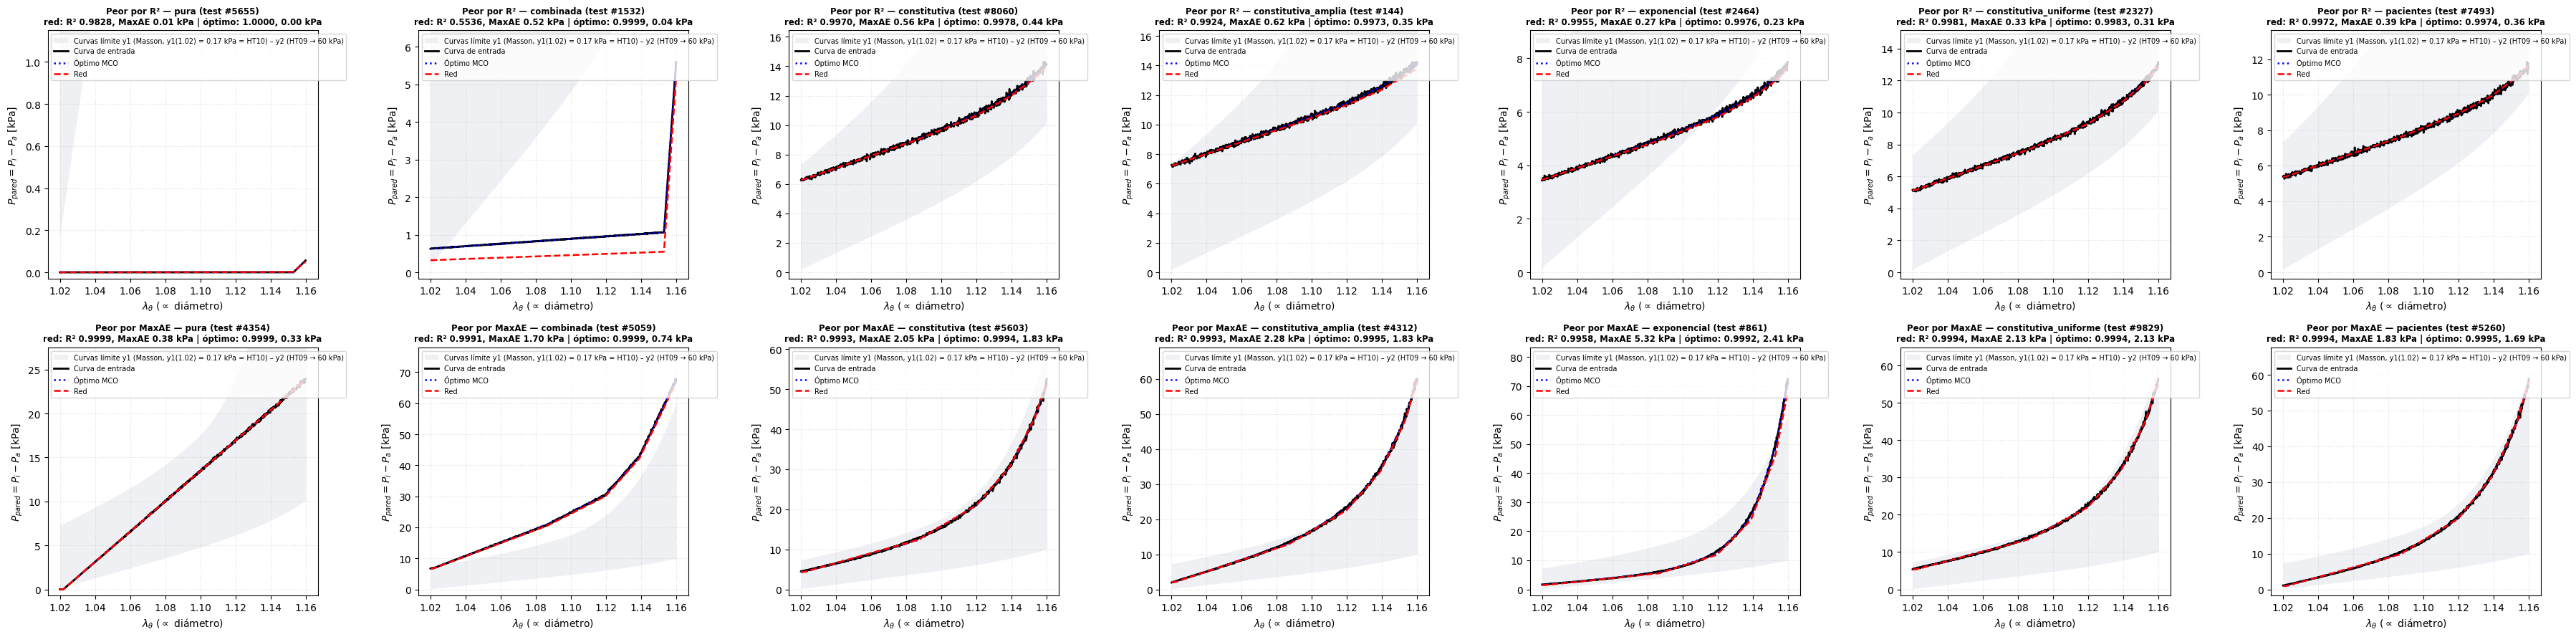

In [20]:
# CELDA 16: EVALUACIÓN EN TEST — LÁMINAS, EXCESO DE LA RED SOBRE EL ÓPTIMO, CRITERIO Y PEORES CASOS
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

M_RN, M_OPT = metricas(B_IN, B_RN), metricas(B_IN, B_OPT)
E0_RN, E0_OPT = metricas(B_LIMPIO, B_RN)["MaxAE_rel"], metricas(B_LIMPIO, B_OPT)["MaxAE_rel"]
fisio = np.isin(FAM_T, FAMILIAS_OBJETIVO)
for titulo, m in [("todas las familias", np.ones_like(fisio)), ("familias fisiológicas", fisio)]:
    d = C_RN[m] - C_OPT[m]
    print(f"Láminas, {titulo} (n = {m.sum()}): R² {np.round(1 - (d ** 2).sum(0) / ((C_OPT[m] - C_OPT[m].mean(0)) ** 2).sum(0), 6)} | "
          f"MAE {np.abs(d).mean(0).round(4)}")

RESUMEN = pd.DataFrame({FAMILIAS[f]: {"n": m.sum(), "NRMSE óptimo %": M_OPT["NRMSE"][m].mean(), "NRMSE red %": M_RN["NRMSE"][m].mean(),
                                      "exceso %": (M_RN["NRMSE"][m].mean() / M_OPT["NRMSE"][m].mean() - 1) * 100,
                                      "R² red mín.": M_RN["R2"][m].min(), "peor (test #)": int(np.where(m)[0][np.argmin(M_RN["R2"][m])]),
                                      f"red cumple ≤{ERROR_MAX_PCT:g}% %": 100 * np.mean(E0_RN[m] <= ERROR_MAX_PCT),
                                      "red máx. %": E0_RN[m].max(), f"MCO cumple ≤{ERROR_MAX_PCT:g}% %": 100 * np.mean(E0_OPT[m] <= ERROR_MAX_PCT),
                                      "MCO máx. %": E0_OPT[m].max()} for f in FAMILIAS for m in [FAM_T == f]}).T
print("\nReconstrucción contra la curva de entrada; criterio contra la curva sin ruido. Exceso = NRMSE red / NRMSE óptimo − 1.")
print(RESUMEN.round(3).to_string())
RESUMEN.to_csv(f"resumen_test_por_familia_{VERSION}.csv")
pd.DataFrame(np.column_stack([idx_test, FAM_T, M_RN["NRMSE"], M_OPT["NRMSE"], E0_RN, C_OPT, C_RN]),
             columns=["idx", "familia", "NRMSE_red", "NRMSE_opt", "MaxAE_rel_red_limpia"]
             + [f"c{j+1}_{t}" for t in ("mco", "red") for j in range(len(NUDOS))]).to_csv(f"metricas_test_por_curva_{VERSION}.csv", index=False)

COL = dict(zip(sorted(FAMILIAS), ["#d62728", "#2ca02c", "#1f77b4", "#ff7f0e", "#9467bd", "#8c564b", "#17becf"]))
for nombre, fams in [("todas", sorted(FAMILIAS)), ("fisiologicas", FAMILIAS_OBJETIVO)]:
    fig, axes = plt.subplots(1, len(NUDOS), figsize=(4.4 * len(NUDOS), 4.2))
    for j, ax in enumerate(axes):
        for f in fams:
            m = FAM_T == f
            ax.scatter(C_OPT[m, j], C_RN[m, j], s=10, alpha=0.35, color=COL[f], edgecolors="none", label=FAMILIAS[f])
        lim = [C_OPT[np.isin(FAM_T, fams), j].min(), C_OPT[np.isin(FAM_T, fams), j].max()]
        ax.plot(lim, lim, "k--", lw=1.2)
        ax.set(title=f"c{j+1} — {nombre}", xlabel="MCO (etiqueta)", ylabel="Red")
        ax.grid(alpha=0.4, ls="--")
    axes[0].legend(fontsize=7, markerscale=2)
    plt.tight_layout()
    plt.savefig(f"diagnostico_coeficientes_{nombre}_{VERSION}.png", dpi=300, bbox_inches="tight")
    plt.show()

ymax = np.maximum(B_IN.max(1, keepdims=True), 1.0)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(15, 5))
le = np.log10(np.clip(1 - M_RN["R2"], 1e-8, None))
for f in FAMILIAS:
    a1.hist(le[FAM_T == f], bins=np.linspace(le.min(), le.max(), 50), alpha=0.55, color=COL[f], label=FAMILIAS[f])
a1.set(yscale="log", xlabel=r"$\log_{10}(1 - R^2)$ red vs. entrada (izquierda = mejor)", ylabel="Curvas")
for d, c, n in [((B_IN - B_RN) / ymax * 100, "#9467bd", "entrada − red (total)"), ((B_OPT - B_RN) / ymax * 100, "#ef4444", "óptimo − red (atribuible a la red)")]:
    a2.hist(d.ravel(), bins=200, density=True, alpha=0.5, color=c, label=n)
a2.set(yscale="log", xlabel="Residuo [% del máximo de cada curva]", ylabel="Densidad")
for a in (a1, a2):
    a.legend(fontsize=8)
    a.grid(alpha=0.4, ls="--")
plt.tight_layout()
plt.savefig(f"distribucion_residuos_{VERSION}.png", dpi=300, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(2, len(FAMILIAS), figsize=(5.2 * len(FAMILIAS), 9))
for c, f in enumerate(FAMILIAS):
    m = np.where(FAM_T == f)[0]
    for r, (s, crit) in enumerate([(m[np.argmin(M_RN["R2"][m])], "R²"), (m[np.argmax(M_RN["MaxAE"][m])], "MaxAE")]):
        panel(axes[r, c], s, f"Peor por {crit} — {FAMILIAS[f]} (test #{s})\nred: R² {M_RN['R2'][s]:.4f}, MaxAE {M_RN['MaxAE'][s]:.2f} kPa"
                             f" | óptimo: {M_OPT['R2'][s]:.4f}, {M_OPT['MaxAE'][s]:.2f} kPa")
plt.tight_layout()
plt.savefig(f"peores_casos_test_{VERSION}.png", dpi=300, bbox_inches="tight")
plt.show()

## Celda 17 — Ley de Fung (nunca vista) y control de clase

In [21]:
# CELDA 17: GENERALIZACIÓN A UNA LEY NUNCA VISTA (Fung) Y CONTROL DE CLASE A LA ENTRADA
#   Fung: P = C + A·(exp(B·(λ − λ_min)) − 1), parámetros mezclados de los ajustes a sujetos de entrenamiento.
#   Control de clase: debe aceptar curvas J (Fung, sujetos) y rechazar sujetos de test modulados con una oscilación.
import numpy as np
from scipy.optimize import curve_fit

N_OOD, RUIDO_OOD = 300, 0.01
rng_ood = np.random.default_rng(2027)
fung = lambda x, a, b, c: c + a * (np.exp(b * (x - X_MIN)) - 1.0)
P_FUNG = np.array([curve_fit(fung, X, y, p0=(5.0, 20.0, max(float(y[0]), 0.01)), bounds=([1e-6, 1e-3, 0], [1e4, 200, 1e3]),
                             maxfev=20000)[0] for y in POB_Y[MASK_TRAIN]])
Y_fung = []
while len(Y_fung) < N_OOD:
    k = rng_ood.integers(2, 4)
    idx = rng_ood.choice(len(P_FUNG), size=k, replace=False)
    y = fung(X, *np.exp(rng_ood.dirichlet(np.ones(k)) @ np.log(P_FUNG[idx]) + rng_ood.normal(0.0, 0.10, size=3)))
    if y.min() > 0 and y.max() <= Y_TECHO:
        Y_fung.append(y)
Y_fung = np.array(Y_fung)
Y_fung_r = np.maximum(Y_fung + rng_ood.normal(0.0, RUIDO_OOD, size=Y_fung.shape) * np.abs(Y_fung), 0.0)
Mf_rn, Mf_opt = metricas(Y_fung_r, predecir(Y_fung_r) @ A.T), metricas(Y_fung_r, mco(Y_fung_r) @ A.T)
i = int(np.argmin(Mf_rn["R2"]))
print(f"🧪 Fung ({N_OOD} curvas, ruido 1 %, {np.mean((Y_fung < Y1) | (Y_fung > Y2)):.1%} de puntos fuera de y1–y2): "
      f"NRMSE red {Mf_rn['NRMSE'].mean():.3f}% | óptimo {Mf_opt['NRMSE'].mean():.3f}% | "
      f"exceso {(Mf_rn['NRMSE'].mean() / Mf_opt['NRMSE'].mean() - 1) * 100:+.1f}% | peor R² red {Mf_rn['R2'][i]:.5f} "
      f"(óptimo {Mf_opt['R2'][i]:.5f}) | MCO fabricable {np.mean((mco(Y_fung_r) >= 0).all(1)):.1%}")

t = X - X_MIN
Y_mod = []
for y in POB_Y[MASK_TEST]:
    for _ in range(max(1, N_OOD // (4 * MASK_TEST.sum()))):
        f, a = rng_ood.uniform(1.0, 3.0), rng_ood.uniform(0.10, 0.30)
        Y_mod.append(y * (1.0 + a * np.sin(2 * np.pi * f * t / t[-1] + rng_ood.uniform(0, 2 * np.pi))))
Y_mod = np.array(Y_mod)
Y_mod_r = np.maximum(Y_mod + rng_ood.normal(0.0, RUIDO_OOD, size=Y_mod.shape) * np.abs(Y_mod), 0.0)
no_J = np.array([not all(diagnostico_forma(y)) for y in Y_mod])
acepta = lambda Y: np.array([distancia_clase(y) <= TOL_CLASE_NRMSE for y in Y])
a_mod = acepta(Y_mod_r)
print(f"🛂 Control de clase (≤ {TOL_CLASE_NRMSE}%): acepta {acepta(Y_fung_r).mean():.1%} de las Fung y {acepta(POB_Y).mean():.0%} "
      f"de los sujetos | rechaza {(~a_mod[no_J]).mean():.1%} de las moduladas fuera de la clase (n = {no_J.sum()}); "
      f"acepta {a_mod[~no_J].mean():.1%} de las que siguieron siendo J (n = {(~no_J).sum()})")

🧪 Fung (300 curvas, ruido 1 %, 0.8% de puntos fuera de y1–y2): NRMSE red 1.000% | óptimo 0.910% | exceso +10.0% | peor R² red 0.99408 (óptimo 0.99761) | MCO fabricable 100.0%
🛂 Control de clase (≤ 2.0%): acepta 100.0% de las Fung y 100% de los sujetos | rechaza 95.7% de las moduladas fuera de la clase (n = 47); acepta 73.9% de las que siguieron siendo J (n = 23)


## Celda 18 — Muestras aleatorias de test

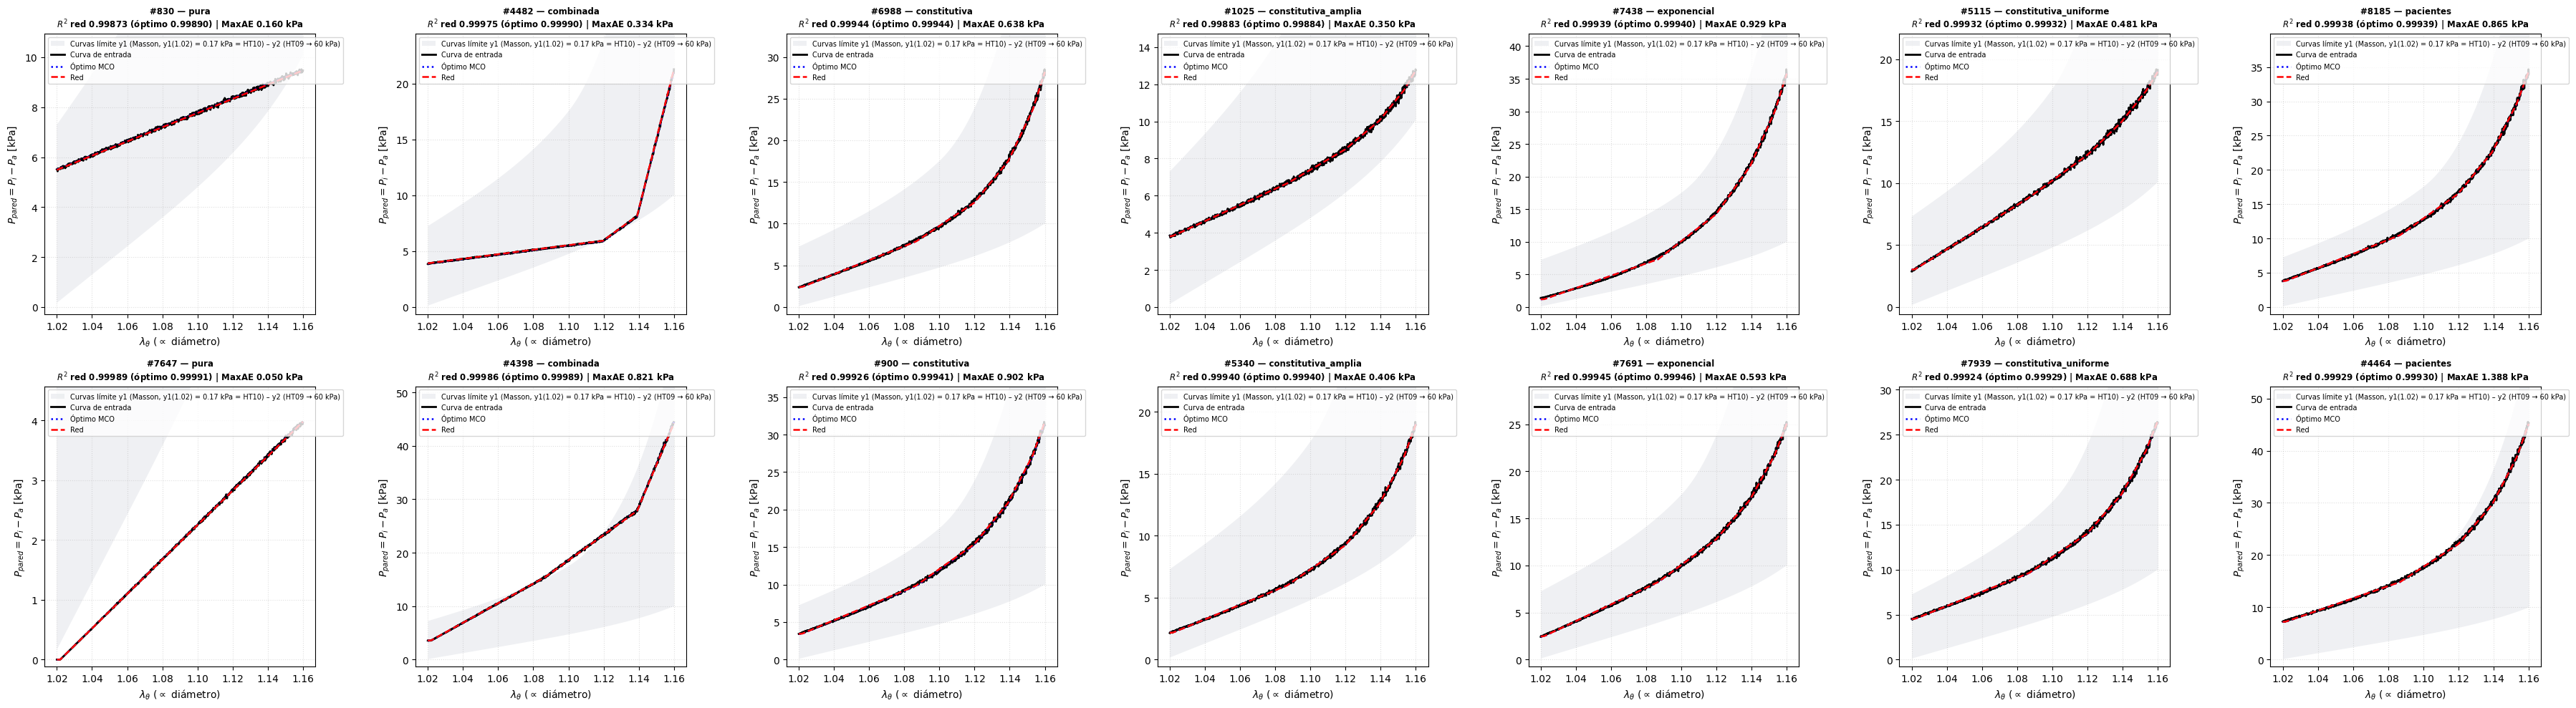

In [22]:
# CELDA 18: MUESTRAS ALEATORIAS DE TEST (2 por familia; escala vertical por panel)
import numpy as np
import matplotlib.pyplot as plt

rng_plot = np.random.default_rng(SEED)
muestras = [rng_plot.choice(np.where(FAM_T == f)[0], size=2, replace=False) for f in sorted(FAMILIAS)]
fig, axes = plt.subplots(2, len(FAMILIAS), figsize=(5.2 * len(FAMILIAS), 10))
for c, (f, ss) in enumerate(zip(sorted(FAMILIAS), muestras)):
    for r, s in enumerate(ss):
        panel(axes[r, c], s, f"#{s} — {FAMILIAS[f]}\n$R^2$ red {M_RN['R2'][s]:.5f} (óptimo {M_OPT['R2'][s]:.5f}) | "
                             f"MaxAE {M_RN['MaxAE'][s]:.3f} kPa")
plt.tight_layout()
plt.savefig(f"reconstruccion_ejemplos_{VERSION}.png", dpi=300, bbox_inches="tight")
plt.show()

## Celda 19 — Diseñador de injerto

🫀 Mean HT | curva J: sí | dentro de y1–y2: True | fabricable (c ≥ 0): True
              MCO      red  diferencia
material                              
1         9.52484  9.54547     0.02062
2         8.10372  8.12263     0.01891
3         7.94066  7.92759    -0.01308
4         6.74086  6.75092     0.01006
5         6.72461  6.72637     0.00176
6         5.67025  5.66802    -0.00223
Total de láminas: MCO 44.705 | red 44.741
           R2      RMSE     MaxAE     NRMSE  MaxAE_rel
MCO  0.999786  0.106214  0.276481  0.368207   0.958462
red  0.999776  0.108526  0.252160  0.376221   0.874147

🧵 Injerto: radio de reposo = 0.8271·R_ref = 2.83 mm (R_ref = 3.42 mm), sin pretensado | P en λ = 1.16: 32.33 kPa (242 mmHg)
          nudo λ  holgura de fibra [%]  láminas c  C_LAM  K de 1 lámina [N/m]  E (t=0.1 mm) [MPa]  K total [N/m]  aporte P λ=1.16 [kPa]  deform. máx. [%]
material                                                                                                                       

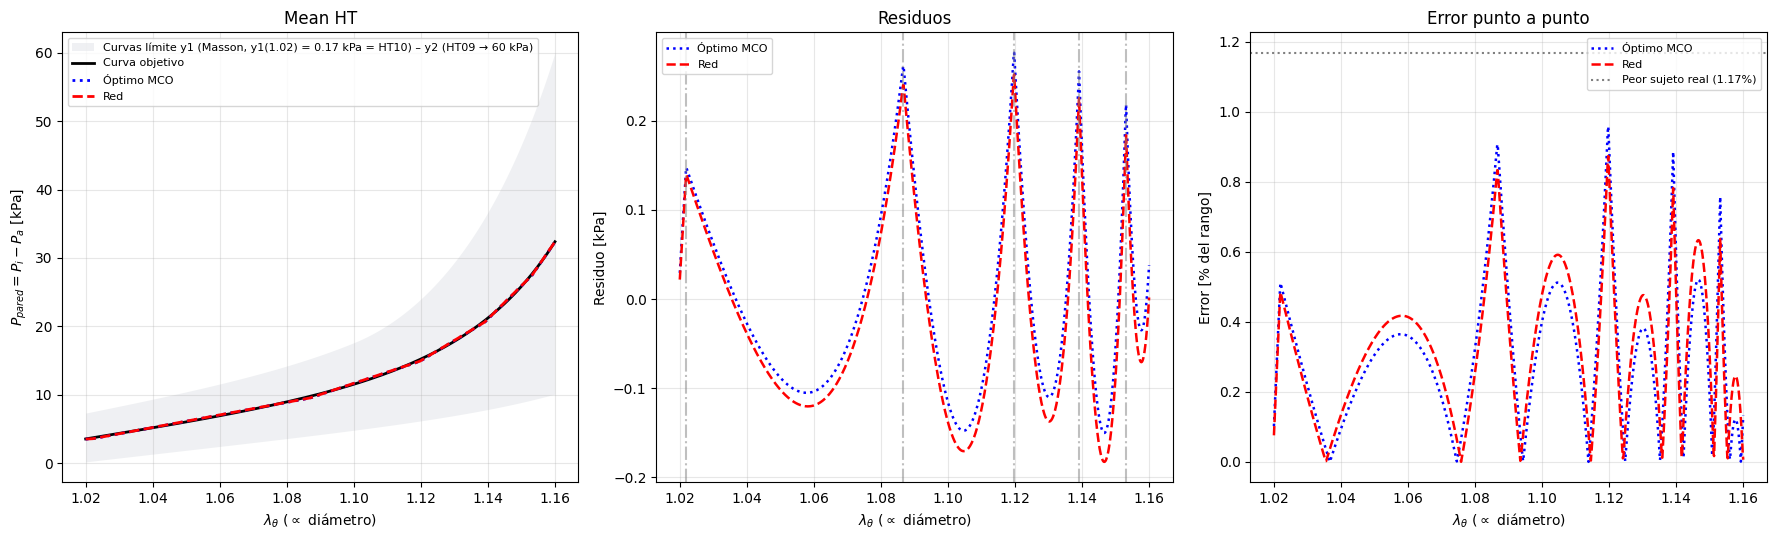

In [23]:
# CELDA 19: DISEÑADOR DE INJERTO — curva presión–diámetro → láminas de cada material
#   MODO = "masson": un sujeto ("HT07") o una curva media ("Mean HT") | "excel": columnas (λθ, P [kPa]) | "puntos": PUNTOS
#   Resultado del método: MCO exacto (red + pulido si la curva es J; MCO directo si no). La red sola se muestra para comparar.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import PchipInterpolator

MODO, SUJETO_EVAL = "masson", "Mean HT"
ARCHIVO_CURVA = "Curva_J.xlsx"
PUNTOS = [(1.07, 7.0), (1.10, 12.0), (1.13, 20.0), (1.16, 36.0)]     # (λθ, P_pared [kPa]), interpolación PCHIP

if MODO == "masson":
    y_t = MEDIAS[SUJETO_EVAL] if SUJETO_EVAL in MEDIAS else POB_Y[(POB.id == SUJETO_EVAL).to_numpy()][0]
    R_suj = R_REF if SUJETO_EVAL in MEDIAS else float(np.deg2rad(POB.Theta0_deg[POB.id == SUJETO_EVAL]).iloc[0]
                                                      * POB.Rm_mm[POB.id == SUJETO_EVAL].iloc[0] / np.pi)
else:
    xu, yu = (np.array(PUNTOS, float).T if MODO == "puntos" else pd.read_excel(ARCHIVO_CURVA, header=None).to_numpy(float)[:, :2].T)
    o = np.argsort(xu)
    y_t = PchipInterpolator(xu[o], yu[o], extrapolate=False)(X) if MODO == "puntos" else np.interp(X, xu[o], yu[o])
    y_t, R_suj = np.where(np.isnan(y_t), np.interp(X, xu[o], yu[o]), y_t), R_REF
en_clase = distancia_clase(y_t) <= TOL_CLASE_NRMSE
c_opt, c_rn = mco(y_t), predecir(y_t)
m_opt, m_rn = metricas(y_t, A @ c_opt), metricas(y_t, A @ c_rn)
print(f"🫀 {SUJETO_EVAL if MODO == 'masson' else MODO} | curva J: {'sí' if en_clase else 'NO (resultado = MCO directo)'} | "
      f"dentro de y1–y2: {bool(dentro_espacio(y_t)[0])} | fabricable (c ≥ 0): {bool((c_opt >= 0).all())}")
print(pd.DataFrame({"MCO": c_opt, "red": c_rn, "diferencia": c_rn - c_opt}, index=pd.Index(range(1, len(NUDOS) + 1), name="material"))
      .round(5).to_string())
print(f"Total de láminas: MCO {c_opt.sum():.3f} | red {c_rn.sum():.3f}")
print(pd.DataFrame({"MCO": m_opt, "red": m_rn}).T.round(6).to_string())

DISENO = pd.DataFrame({"nudo λ": NUDOS, "holgura de fibra [%]": (NUDOS / NUDOS[0] - 1) * 100, "láminas c": c_opt,
                       "C_LAM": C_LAM, "K de 1 lámina [N/m]": S * R_suj * NUDOS ** 2,
                       f"E (t={ESPESOR_LAMINA_MM:g} mm) [MPa]": S * R_suj * NUDOS ** 2 / ESPESOR_LAMINA_MM * 1e-3,
                       "K total [N/m]": c_opt * S * R_suj * NUDOS ** 2, f"aporte P λ={X_MAX:g} [kPa]": c_opt * A[-1],
                       "deform. máx. [%]": (X_MAX / NUDOS - 1) * 100}, index=pd.Index(range(1, len(NUDOS) + 1), name="material"))
print(f"\n🧵 Injerto: radio de reposo = {NUDOS[0]:.4f}·R_ref = {NUDOS[0] * R_suj:.2f} mm (R_ref = {R_suj:.2f} mm), sin pretensado | "
      f"P en λ = {X_MAX:g}: {A[-1] @ c_opt:.2f} kPa ({A[-1] @ c_opt / 0.133322:.0f} mmHg)")
print(DISENO.round(4).to_string())
DISENO.to_csv(f"diseno_injerto_{VERSION}.csv")

fig, ax = plt.subplots(1, 3, figsize=(18, 5.5))
banda(ax[0])
for b, st, n in [(y_t, "k-", "Curva objetivo"), (A @ c_opt, "b:", "Óptimo MCO"), (A @ c_rn, "r--", "Red")]:
    ax[0].plot(X, b, st, lw=2, label=n)
    if n != "Curva objetivo":
        ax[1].plot(X, y_t - b, st, lw=1.8, label=n)
        ax[2].plot(X, np.abs(y_t - b) / np.ptp(y_t) * 100, st, lw=1.8, label=n)
for k_ in NUDOS[NUDOS >= X_MIN]:
    ax[1].axvline(k_, color="gray", ls="-.", alpha=0.5)
ax[2].axhline(PISO_MAXAE, color="gray", ls=":", label=f"Peor sujeto real ({PISO_MAXAE:.2f}%)")
for a, yl, ti in zip(ax, [ETQ_Y, "Residuo [kPa]", "Error [% del rango]"], [SUJETO_EVAL, "Residuos", "Error punto a punto"]):
    a.set(xlabel=ETQ_X, ylabel=yl, title=ti)
    a.legend(fontsize=8)
    a.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f"evaluacion_inferencia_curva_j_{VERSION}.png", dpi=300, bbox_inches="tight")
plt.show()

## Celda 20 — Reproducción de láminas aisladas

 material  láminas a  R2_red  error c activo %  crosstalk máx.
        1       0.25 0.98883           1.67421         0.00078
        1       0.50 0.99940           0.39976         0.00070
        1       1.00 0.99977           0.21619         0.00084
        1       2.00 0.99999          -0.07048         0.00121
        1       4.00 0.99999          -0.04920         0.00143
        2       0.25 0.99993           0.05331         0.00251
        2       0.50 1.00000          -0.15244         0.00379
        2       1.00 0.99997           0.30377         0.00508
        2       2.00 1.00000           0.04591         0.00159
        2       4.00 1.00000           0.11092         0.00313
        3       0.25 0.99983          -2.23601         0.00172
        3       0.50 0.99997          -0.74645         0.00148
        3       1.00 1.00000           0.20183         0.00241
        3       2.00 1.00000          -0.04297         0.00303
        3       4.00 1.00000          -0.09384         

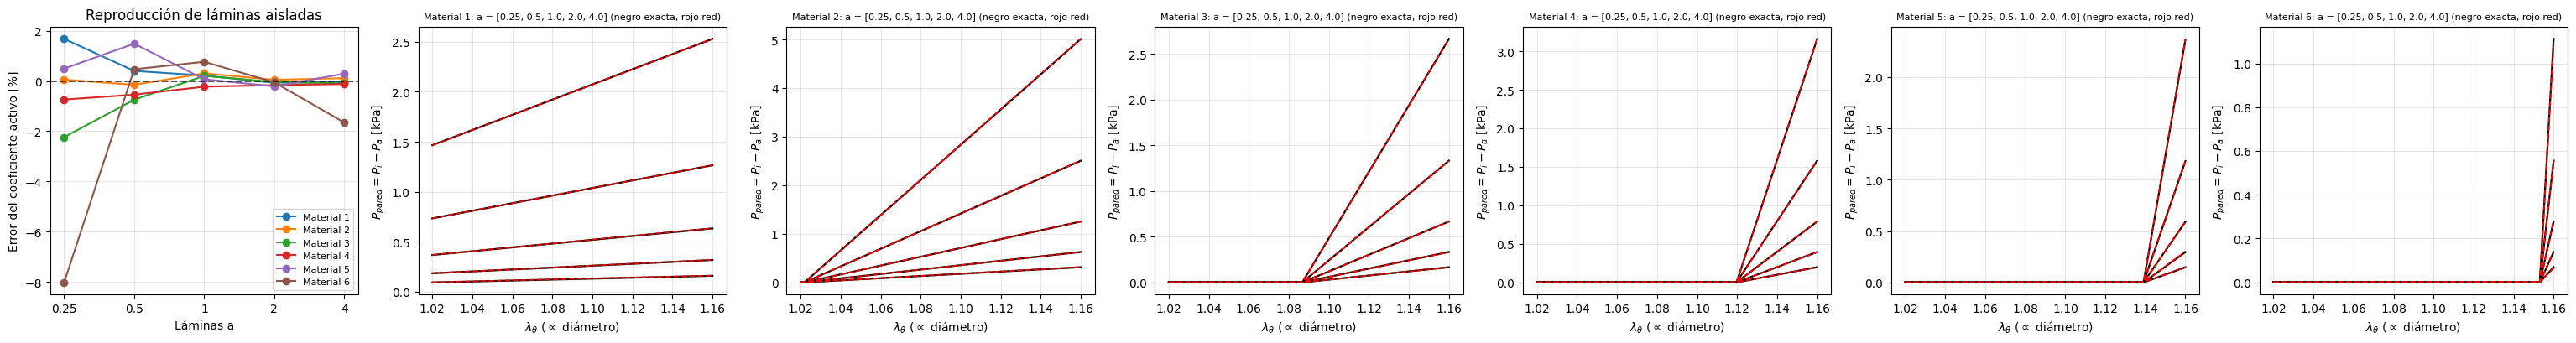

In [24]:
# CELDA 20: REPRODUCCIÓN DE LÁMINAS AISLADAS (entrada y = a·A_j; respuesta exacta c = a·e_j)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

AMPLITUDES = [0.25, 0.5, 1.0, 2.0, 4.0]                              # láminas del diseño
nb = len(NUDOS)
C_EX = np.vstack([a * np.eye(nb)[j] for j in range(nb) for a in AMPLITUDES])
Y_B = C_EX @ A.T
C_B = predecir(Y_B)
j_act = np.repeat(np.arange(nb), len(AMPLITUDES))
act = C_B[np.arange(len(C_B)), j_act]
DF_B = pd.DataFrame({"material": j_act + 1, "láminas a": np.tile(AMPLITUDES, nb), "R2_red": metricas(Y_B, C_B @ A.T)["R2"],
                     "error c activo %": (act / C_EX.max(1) - 1) * 100,
                     "crosstalk máx.": np.abs(np.where(C_EX > 0, 0.0, C_B)).max(1)})
print(DF_B.round(5).to_string(index=False))
print(f"Peor |error| del coeficiente activo: {DF_B['error c activo %'].abs().max():.3f}% | crosstalk máx.: {DF_B['crosstalk máx.'].max():.5f} láminas")
DF_B.to_csv(f"test_reproduccion_bases_{VERSION}.csv", index=False)

fig, ax = plt.subplots(1, nb + 1, figsize=(4.4 * (nb + 1), 4.2))
for j in range(nb):
    d = DF_B[DF_B.material == j + 1]
    ax[0].plot(d["láminas a"], d["error c activo %"], "o-", label=f"Material {j+1}")
    m = j_act == j
    ax[j + 1].plot(X, Y_B[m].T, "k-", lw=1.6)
    ax[j + 1].plot(X, (C_B[m] @ A.T).T, "r--", lw=1.3)
    ax[j + 1].set(title=f"Material {j+1}: a = {AMPLITUDES} (negro exacta, rojo red)", xlabel=ETQ_X, ylabel=ETQ_Y)
ax[0].axhline(0, color="k", ls="--", alpha=0.6)
ax[0].set(xscale="log", xlabel="Láminas a", ylabel="Error del coeficiente activo [%]", title="Reproducción de láminas aisladas")
ax[0].set_xticks(AMPLITUDES, [f"{a:g}" for a in AMPLITUDES])
ax[0].minorticks_off()
ax[0].legend(fontsize=8)
for a in ax:
    a.grid(alpha=0.3)
for a in ax[1:]:
    a.title.set_fontsize(8)
plt.tight_layout()
plt.savefig(f"test_reproduccion_bases_{VERSION}.png", dpi=300, bbox_inches="tight")
plt.show()

## Celda 21 — Las bases con su fórmula

Fórmulas verificadas contra las bases: |diferencia| máx. = 0.0e+00 kPa
   A_1(λ) = 1,90·max(0, λ − 0,8271)
   A_2(λ) = 9,07·max(0, λ − 1,0219)
   A_3(λ) = 9,08·max(0, λ − 1,0867)
   A_4(λ) = 19,61·max(0, λ − 1,1197)
   A_5(λ) = 28,24·max(0, λ − 1,1391)
   A_6(λ) = 40,27·max(0, λ − 1,1531)


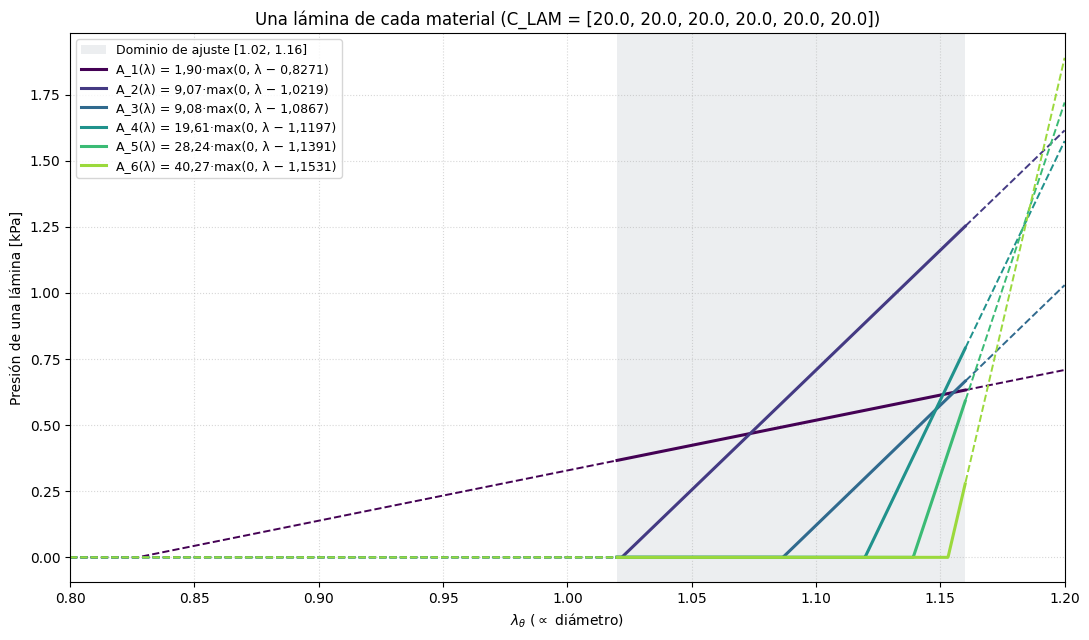

In [25]:
# CELDA 21: LAS BASES CON SU FÓRMULA (continua: dominio de ajuste; punteada: extensión de la misma fórmula)
import numpy as np
import matplotlib.pyplot as plt

LAMBDA_GRAF = (0.80, 1.20)                                           # rango del gráfico (p. ej. (0.0, 1.2))
lam = np.linspace(*LAMBDA_GRAF, 2401)
Ab = np.maximum(0.0, lam[:, None] - NUDOS) * S
dentro = (lam >= X_MIN) & (lam <= X_MAX)
print(f"Fórmulas verificadas contra las bases: |diferencia| máx. = {np.abs(np.maximum(0, X[:, None] - NUDOS) * S - A).max():.1e} kPa")
fig, ax = plt.subplots(figsize=(11, 6.5))
ax.axvspan(X_MIN, X_MAX, color="#e5e7eb", alpha=0.7, lw=0, label=f"Dominio de ajuste [{X_MIN}, {X_MAX}]")
for j, c in enumerate(plt.cm.viridis(np.linspace(0, 0.85, len(NUDOS)))):
    f = f"A_{j+1}(λ) = {S[j]:.2f}·max(0, λ − {NUDOS[j]:.4f})".replace(".", ",")
    print("   " + f)
    ax.plot(lam, np.where(dentro, Ab[:, j], np.nan), color=c, lw=2.2, label=f)
    ax.plot(lam, np.where(dentro, np.nan, Ab[:, j]), color=c, lw=1.4, ls="--")
ax.set(xlim=LAMBDA_GRAF, xlabel=ETQ_X, ylabel="Presión de una lámina [kPa]",
       title=f"Una lámina de cada material (C_LAM = {C_LAM.tolist()})")
ax.grid(alpha=0.5, ls=":")
ax.legend(fontsize=9, loc="upper left")
plt.tight_layout()
plt.savefig(f"bases_funcionales_{VERSION}.png", dpi=300, bbox_inches="tight")
plt.show()

## Celda 22 — Extrapolación fuera del dominio de ajuste

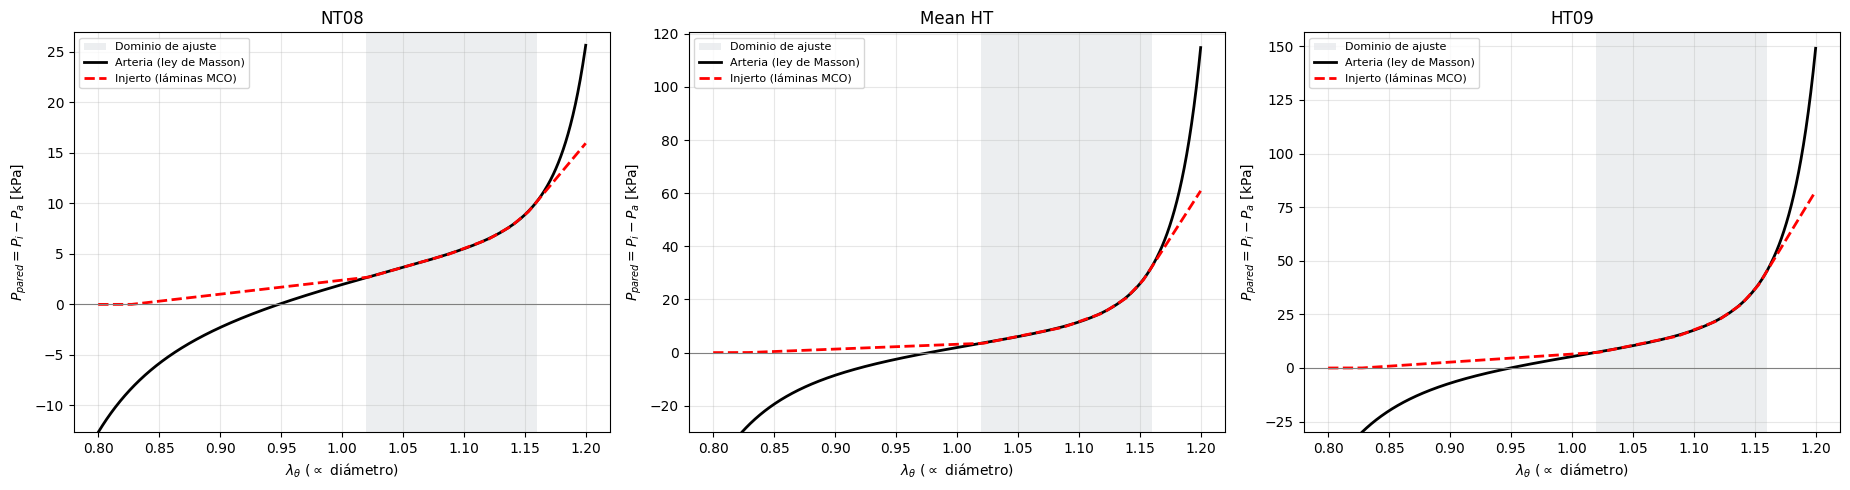

                                        NT08       Mean HT          HT09
λ=0.8: arteria / injerto [kPa]   -12.7 / 0.0   -45.2 / 0.0   -50.2 / 0.0
λ=0.9: arteria / injerto [kPa]    -2.3 / 1.0    -8.5 / 1.3    -7.1 / 2.7
λ=0.95: arteria / injerto [kPa]    0.1 / 1.7    -2.5 / 2.2     0.1 / 4.6
λ=1: arteria / injerto [kPa]       2.0 / 2.4     1.9 / 3.1     5.3 / 6.4
λ=1.18: arteria / injerto [kPa]  14.8 / 13.1   56.2 / 46.6   75.8 / 63.8
λ=1.2: arteria / injerto [kPa]   25.6 / 15.9  114.8 / 60.9  149.1 / 82.5


In [26]:
# CELDA 22: EXTRAPOLACIÓN FUERA DEL DOMINIO DE AJUSTE — injerto (láminas ajustadas en [1,02; 1,16]) vs. arteria
#   Las láminas no se reajustan: se evalúa la misma receta en LAMBDA_EXT. Bajo el primer nudo el injerto no aporta
#   presión (las capas no trabajan a compresión), mientras la ley de Masson da P_pared < 0 (pared comprimida).
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

LAMBDA_EXT = (0.80, 1.20)
CURVAS_EXT = ["NT08", "Mean HT", SUJETO_Y2]                       # sujetos o curvas medias
le = np.linspace(*LAMBDA_EXT, 801)
A_ext = np.maximum(0.0, le[:, None] - NUDOS) * S
fig, axes = plt.subplots(1, len(CURVAS_EXT), figsize=(6.2 * len(CURVAS_EXT), 5))
filas = {}
for ax, k in zip(axes, CURVAS_EXT):
    sub = POB[GRUPOS_MEDIAS[k]] if k in GRUPOS_MEDIAS else POB[POB.id == k]
    y_art = np.mean([curva_objetivo(le, r) for _, r in sub.iterrows()], axis=0)
    y_inj = A_ext @ mco(MEDIAS[k] if k in MEDIAS else POB_Y[(POB.id == k).to_numpy()][0])
    filas[k] = {f"λ={l:g}: arteria / injerto [kPa]": f"{np.interp(l, le, y_art):.1f} / {np.interp(l, le, y_inj):.1f}"
                for l in (0.80, 0.90, 0.95, 1.00, 1.18, 1.20) if LAMBDA_EXT[0] <= l <= LAMBDA_EXT[1]}
    ax.axvspan(X_MIN, X_MAX, color="#e5e7eb", alpha=0.7, lw=0, label="Dominio de ajuste")
    ax.plot(le, y_art, "k-", lw=2, label="Arteria (ley de Masson)")
    ax.plot(le, y_inj, "r--", lw=2, label="Injerto (láminas MCO)")
    ax.axhline(0, color="gray", lw=0.8)
    ax.set(xlabel=ETQ_X, ylabel=ETQ_Y, title=k, ylim=(max(y_art.min(), -30), 1.05 * max(y_art.max(), y_inj.max())))
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8, loc="upper left")
plt.tight_layout()
plt.savefig(f"extrapolacion_{VERSION}.png", dpi=300, bbox_inches="tight")
plt.show()
print(pd.DataFrame(filas).to_string())

## Celda 23 — Diseño fabricable: pared máxima y espesor mínimo de capa (minimax)

In [27]:
# CELDA 23: DISEÑO FABRICABLE — pared ≤ PARED_MAX_MM, cada capa 0 o ≥ ESP_MIN_MM, ajuste minimax
#   Cada material j es una capa de espesor h_j [mm]. 1 mm del material j aporta a_j(λ) = E_j/(R_ref·k_j²)·max(0, λ − k_j) [kPa]
#   (ley de Laplace con R_ref = radio con λθ = 1; E_j = módulo equivalente del material [MPa]).
#   Diseño fabricable: h = argmin max_i |y_i − (A_mm h)_i|  sujeto a  Σh_j ≤ PARED_MAX_MM,  h_j = 0 o h_j ≥ ESP_MIN_MM
#   (programación lineal entera mixta, HiGHS; una variable binaria por material indica si se usa).
#   Con ESPESOR_DISCRETO_MM = t, cada capa es un número entero de láminas de espesor t.
#   «MCO» y «Red» = espesores que resultan de las láminas del MCO y de la red, sin restricciones (para comparar).
import os
import sys
import contextlib
import numpy as np
import pandas as pd
from scipy.optimize import milp, LinearConstraint, Bounds

E_MAT = np.asarray(E_MAT_MPA if E_MAT_MPA is not None else E_REF[N_BASES], float)
assert E_MAT.shape == (N_BASES,), f"E_MAT_MPA o E_REF[{N_BASES}] debe tener {N_BASES} valores (o correr la Celda 26)"
S_MM = E_MAT * 1e3 / (R_REF * NUDOS ** 2)                 # pendiente de 1 mm de cada material [kPa por unidad de λ]
A_MM = G * S_MM                                           # bases por mm de espesor


@contextlib.contextmanager
def _silencio():
    """Silencia los mensajes internos que HiGHS escribe directamente en la salida estándar."""
    sys.stdout.flush()
    fd, nul = os.dup(1), os.open(os.devnull, os.O_WRONLY)
    os.dup2(nul, 1)
    try:
        yield
    finally:
        os.dup2(fd, 1)
        os.close(fd)
        os.close(nul)


def disenar(y, pared=None, hmin=None, paso=None, E=None):
    """Espesores fabricables [mm] y error punto a punto máximo [%] (ver _disenar)."""
    with _silencio():
        return _disenar(y, pared, hmin, paso, E)


def _disenar(y, pared=None, hmin=None, paso=None, E=None):
    """Espesores h [mm] fabricables que minimizan el error punto a punto máximo (en 500 puntos). Devuelve (h, error %)."""
    pared = PARED_MAX_MM if pared is None else pared
    hmin = ESP_MIN_MM if hmin is None else hmin
    paso = ESPESOR_DISCRETO_MM if paso is None else (paso or None)
    B = A_MM if E is None else G * (np.asarray(E, float) * 1e3 / (R_REF * NUDOS ** 2))
    u = paso or 1.0                                       # unidad de la variable: mm (continuo) o láminas (discreto)
    Bs, ys, n = B[::2] * u, y[::2], B.shape[1]
    hmax, lo = pared / u, (np.ceil(hmin / u - 1e-9) if paso else hmin / u)
    if paso:
        hmax = np.floor(hmax + 1e-9)
    m = len(ys)
    eps = 1e-4 * np.ptp(y) / hmax                          # desempate: entre diseños de igual error, la pared más delgada
    cfun = np.r_[np.full(n, eps), np.zeros(n), 1.0]       # variables: h (n), b (n binarias: material usado), τ
    Ah = np.c_[Bs, np.zeros((m, n)), -np.ones(m)]
    An = np.c_[-Bs, np.zeros((m, n)), -np.ones(m)]
    I = np.eye(n)
    filas = [Ah, An, np.r_[np.ones(n), np.zeros(n), 0][None], np.c_[I, -hmax * I, np.zeros(n)], np.c_[-I, lo * I, np.zeros(n)]]
    sup = np.r_[ys, -ys, hmax, np.zeros(n), np.zeros(n)]
    args = dict(integrality=np.r_[np.full(n, 1 if paso else 0), np.ones(n), 0],
                bounds=Bounds(np.zeros(2 * n + 1), np.r_[np.full(n, hmax), np.ones(n), np.inf]),
                constraints=LinearConstraint(np.vstack(filas), -np.inf, sup))
    for opc in (dict(time_limit=60), dict(time_limit=60, presolve=False)):   # si HiGHS falla, se reintenta sin presolve
        r = milp(cfun, options=opc, **args)
        if r.x is not None:
            break
    if r.x is not None:
        h = np.where(r.x[n:2 * n] > 0.5, r.x[:n] * u, 0.0)
    else:                                                  # respaldo: se prueba cada subconjunto de materiales usados (2^N problemas sin binarias)
        mejor = (np.inf, np.zeros(n))
        for k in range(1, 2 ** n):
            usa = np.array([(k >> j) & 1 for j in range(n)], bool)
            rk = milp(np.r_[np.where(usa, eps, 0.0), 1.0], integrality=np.r_[np.full(n, 1 if paso else 0), 0],
                      bounds=Bounds(np.r_[np.where(usa, lo, 0.0), 0], np.r_[np.where(usa, hmax, 0.0), np.inf]),
                      constraints=LinearConstraint(np.vstack([np.c_[Bs, -np.ones(m)], np.c_[-Bs, -np.ones(m)], np.r_[np.ones(n), 0][None]]),
                                                   -np.inf, np.r_[ys, -ys, hmax]), options=dict(time_limit=20))
            if rk.x is not None and rk.x[-1] < mejor[0]:
                mejor = (rk.x[-1], rk.x[:n] * u)
        h = mejor[1]
    if paso:
        h = np.round(h / u) * u
    return h, np.abs(y - B @ h).max() / np.ptp(y) * 100


def espesor_red(c):
    """Espesores [mm] equivalentes a las láminas reales c del diseño (escala C_LAM): misma pendiente por capa."""
    return np.atleast_2d(c) * S / S_MM


_Y = np.vstack([POB_Y, *MEDIAS.values(), Y1, Y2])
_nom = list(POB.id) + list(MEDIAS) + ["y1", "y2"]
_grupo = list(POB.grupo) + ["media"] * len(MEDIAS) + ["límite"] * 2
H_RED = espesor_red(predecir(_Y))
E_RED = np.abs(_Y - H_RED @ A_MM.T).max(1) / np.ptp(_Y, 1) * 100
H_MCO = espesor_red(mco(_Y))                              # mismo cálculo con las láminas del MCO
E_MCO = np.abs(_Y - H_MCO @ A_MM.T).max(1) / np.ptp(_Y, 1) * 100
_res = [disenar(y) for y in _Y]
H_FAB, E_FAB = np.array([r[0] for r in _res]), np.array([r[1] for r in _res])
DISENOS = pd.DataFrame(np.c_[H_FAB, H_FAB.sum(1), E_FAB, H_MCO.sum(1), E_MCO, H_RED.sum(1), E_RED],
                       index=pd.Index(_nom, name="curva"),
                       columns=[f"h{j + 1} [mm]" for j in range(N_BASES)] + ["pared [mm]", "error %", "pared MCO [mm]", "error MCO %", "pared red [mm]", "error red %"])
DISENOS.insert(0, "grupo", _grupo)
DISENOS.to_csv(f"disenos_fabricables_{VERSION}.csv")

print(f"Materiales: E = {E_MAT.round(3).tolist()} MPa | 1 mm aporta S = {S_MM.round(1).tolist()} kPa por unidad de λ (R_ref = {R_REF:.2f} mm)")
print(f"Restricciones: pared ≤ {PARED_MAX_MM:g} mm, cada capa 0 o ≥ {ESP_MIN_MM:g} mm"
      f"{'' if ESPESOR_DISCRETO_MM is None else f', láminas enteras de {ESPESOR_DISCRETO_MM:g} mm'}\n")
_fil = []
for g, m in [("Todos (41)", np.arange(len(POB))), ("NT", np.where(POB.grupo == "NT")[0]), ("HT", np.where(POB.grupo == "HT")[0]),
             ("Curvas medias", np.arange(len(POB), len(POB) + len(MEDIAS))), ("y1 e y2", np.arange(len(_Y) - 2, len(_Y)))]:
    hr = H_RED[m].sum(1)
    _fil.append({"curvas": g, "n": len(m), "fabricable: cumplen 3%": f"{(E_FAB[m] <= ERROR_MAX_PCT).sum()}/{len(m)}",
                 "fabricable: error máx. %": E_FAB[m].max(), "fabricable: error mediano %": np.median(E_FAB[m]),
                 "fabricable: pared mediana [mm]": np.median(H_FAB[m].sum(1)), "capas usadas (mediana)": np.median((H_FAB[m] > 0).sum(1)),
                 "red: pared mediana [mm]": np.median(hr), "red: pared máx. [mm]": hr.max(),
                 "red: cumplen restricciones": f"{((hr <= PARED_MAX_MM + 1e-9) & ((H_RED[m] >= ESP_MIN_MM - 1e-9) | (H_RED[m] <= 1e-9)).all(1)).sum()}/{len(m)}"})
pd.set_option("display.width", 250)
print(pd.DataFrame(_fil).set_index("curvas").round(2).to_string())
_s = slice(0, len(POB))
_peor = DISENOS.iloc[_s]["error %"].sort_values(ascending=False).head(5)
print(f"\nSujetos con mayor error fabricable: " + ", ".join(f"{k} {v:.2f}%" for k, v in _peor.items()))
print("\nDetalle (espesor de cada capa [mm], pared y error punto a punto máximo):")
print(DISENOS.loc[list(MEDIAS) + ["y1", "y2"]].round(3).to_string())

Materiales: E = [0.177, 1.328, 4.861, 2.724, 12.938, 6.352] MPa | 1 mm aporta S = [75.6, 371.8, 1203.2, 635.1, 2914.6, 1396.5] kPa por unidad de λ (R_ref = 3.42 mm)
Restricciones: pared ≤ 1 mm, cada capa 0 o ≥ 0.1 mm

                n fabricable: cumplen 3%  fabricable: error máx. %  fabricable: error mediano %  fabricable: pared mediana [mm]  capas usadas (mediana)  red: pared mediana [mm]  red: pared máx. [mm] red: cumplen restricciones
curvas                                                                                                                                                                                                                           
Todos (41)     41                  36/41                      8.47                         2.36                            0.83                     4.0                     0.78                  1.60                       0/41
NT             16                  13/16                      8.47                         2.56         

## Celda 24 — y2, Mean HT e y1: sin restricciones y fabricable

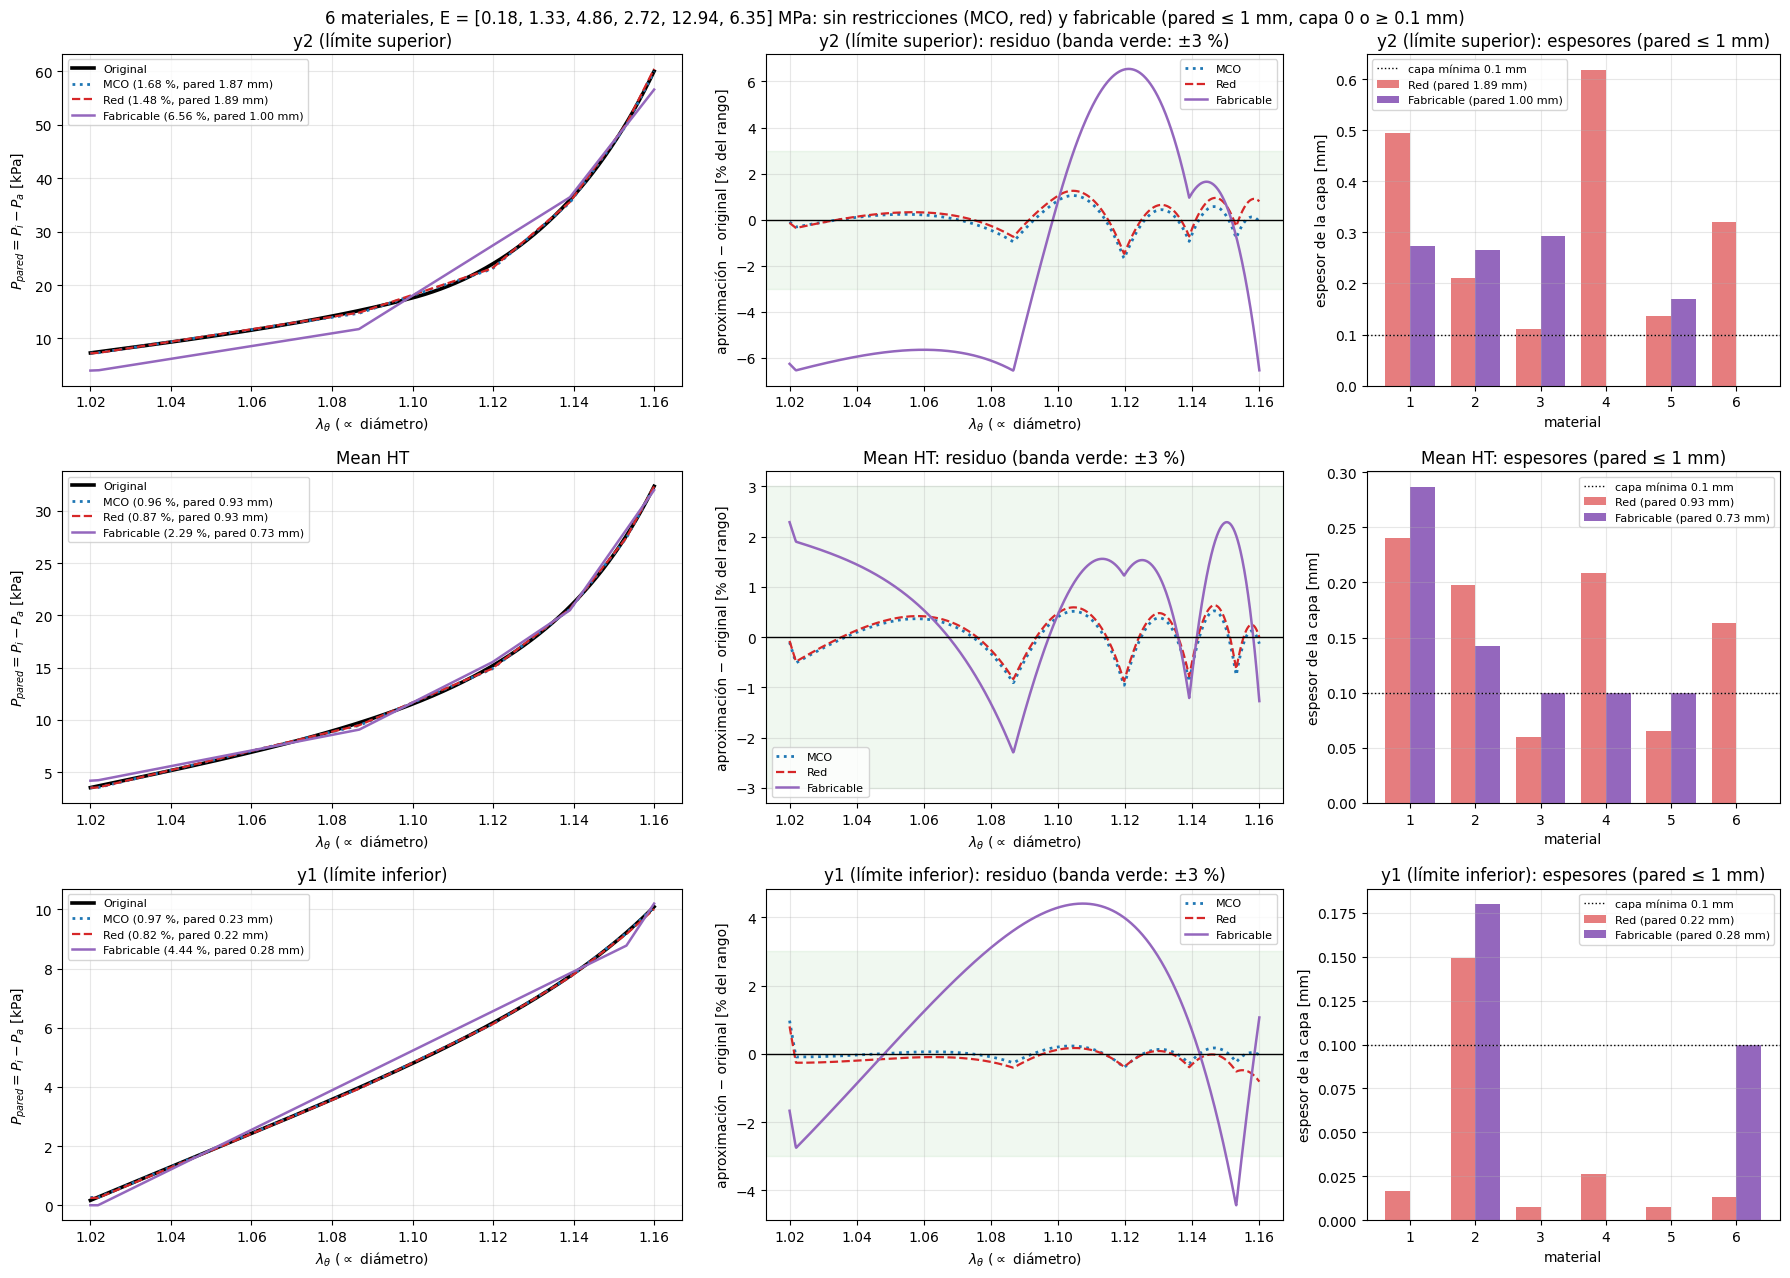

                                 h1 [mm]  h2 [mm]  h3 [mm]  h4 [mm]  h5 [mm]  h6 [mm]  pared [mm]  error máx. %
curva                diseño                                                                                    
y2 (límite superior) MCO           0.497    0.206    0.113    0.617    0.134    0.308       1.875         1.682
                     Red           0.495    0.212    0.111    0.619    0.137    0.321       1.895         1.484
                     Fabricable    0.274    0.265    0.292    0.000    0.169    0.000       1.000         6.555
Mean HT              MCO           0.239    0.198    0.060    0.208    0.065    0.164       0.934         0.958
                     Red           0.240    0.198    0.060    0.208    0.065    0.163       0.935         0.874
                     Fabricable    0.286    0.142    0.100    0.100    0.100    0.000       0.729         2.293
y1 (límite inferior) MCO           0.018    0.149    0.007    0.028    0.008    0.018       0.228       

In [28]:
# CELDA 24: y2, Mean HT e y1 — curva original, MCO y red (sin restricciones) y diseño fabricable
#   Izquierda: curvas (entre paréntesis: error punto a punto máximo y espesor de pared). Centro: residuo en % del rango.
#   Derecha: espesor de cada capa; línea: espesor mínimo de capa; en el título, la pared.
import numpy as np
import matplotlib.pyplot as plt

_CURVAS = {"y2 (límite superior)": "y2", "Mean HT": "Mean HT", "y1 (límite inferior)": "y1"}
_EST = {"MCO": ("tab:blue", ":", 2.0), "Red": ("tab:red", "--", 1.6), "Fabricable": ("tab:purple", "-", 1.8)}
_filas = []
fig, axs = plt.subplots(3, 3, figsize=(18, 13), gridspec_kw=dict(width_ratios=[1.2, 1, 0.8]))
for (tit, nom), (ax, axr, axb) in zip(_CURVAS.items(), axs):
    i = _nom.index(nom)
    y = _Y[i]
    H = {"MCO": espesor_red(mco(y))[0], "Red": H_RED[i], "Fabricable": H_FAB[i]}
    ax.plot(X, y, "k-", lw=2.6, label="Original")
    for k, h in H.items():
        col, ls, lw = _EST[k]
        e = np.abs(y - A_MM @ h).max() / np.ptp(y) * 100
        ax.plot(X, A_MM @ h, color=col, ls=ls, lw=lw, label=f"{k} ({e:.2f} %, pared {h.sum():.2f} mm)")
        axr.plot(X, (A_MM @ h - y) / np.ptp(y) * 100, color=col, ls=ls, lw=lw, label=k)
        _filas.append({"curva": tit, "diseño": k, **{f"h{j + 1} [mm]": v for j, v in enumerate(h)}, "pared [mm]": h.sum(), "error máx. %": e})
    w, j = 0.38, np.arange(1, N_BASES + 1)
    axb.bar(j - w / 2, H["Red"], w, color="tab:red", alpha=0.6, label=f"Red (pared {H['Red'].sum():.2f} mm)")
    axb.bar(j + w / 2, H["Fabricable"], w, color="tab:purple", label=f"Fabricable (pared {H['Fabricable'].sum():.2f} mm)")
    axb.axhline(ESP_MIN_MM, color="k", ls=":", lw=1, label=f"capa mínima {ESP_MIN_MM:g} mm")
    axb.set(xticks=j, xlabel="material", ylabel="espesor de la capa [mm]", title=f"{tit}: espesores (pared ≤ {PARED_MAX_MM:g} mm)")
    axb.legend(fontsize=8)
    for a in (ax, axr, axb):
        a.grid(alpha=0.3)
    ax.set(title=tit, xlabel=ETQ_X, ylabel=ETQ_Y)
    ax.legend(fontsize=8, loc="upper left")
    axr.axhspan(-ERROR_MAX_PCT, ERROR_MAX_PCT, color="tab:green", alpha=0.07)
    axr.axhline(0, color="k", lw=1)
    axr.set(title=f"{tit}: residuo (banda verde: ±{ERROR_MAX_PCT:g} %)", xlabel=ETQ_X, ylabel="aproximación − original [% del rango]")
    axr.legend(fontsize=8)
fig.suptitle(f"{N_BASES} materiales, E = {E_MAT.round(2).tolist()} MPa: sin restricciones (MCO, red) y fabricable "
             f"(pared ≤ {PARED_MAX_MM:g} mm, capa 0 o ≥ {ESP_MIN_MM:g} mm)", fontsize=12)
fig.tight_layout()
plt.savefig(f"curvas_fabricables_{VERSION}.png", dpi=300, bbox_inches="tight")
plt.show()
TABLA_FAB = pd.DataFrame(_filas).set_index(["curva", "diseño"])
print(TABLA_FAB.round(3).to_string())
TABLA_FAB.to_csv(f"tabla_curvas_fabricables_{VERSION}.csv")

## Celda 25 — Estudio de pared

Sujetos (de 41) que cumplen el 3 %, por pared máxima (columnas) y tipo de capa (filas) | E = [0.18, 1.33, 4.86, 2.72, 12.94, 6.35] MPa:
pared máx. [mm]      0.6  0.8  1.0  1.2  1.5
capa                                        
continua ≥ 0 mm       26   32   41   41   41
continua ≥ 0.025 mm   26   32   41   41   41
continua ≥ 0.05 mm    25   31   40   40   40
continua ≥ 0.075 mm   17   28   39   39   39
continua ≥ 0.1 mm      4   17   36   36   36
láminas de 0.1 mm      0    1    3    7    9
láminas de 0.05 mm     8   17   27   30   30

Error punto a punto máximo entre los 41 sujetos [%]:
pared máx. [mm]        0.6    0.8    1.0    1.2    1.5
capa                                                  
continua ≥ 0 mm      17.89   8.38   2.42   1.73   0.99
continua ≥ 0.025 mm  17.89   8.51   2.42   1.91   1.91
continua ≥ 0.05 mm   17.95   8.89   5.37   5.37   5.37
continua ≥ 0.075 mm  18.81   9.19   5.36   5.36   5.36
continua ≥ 0.1 mm    19.67   9.19   8.47   8.47   8.47
láminas de 0.1 mm   

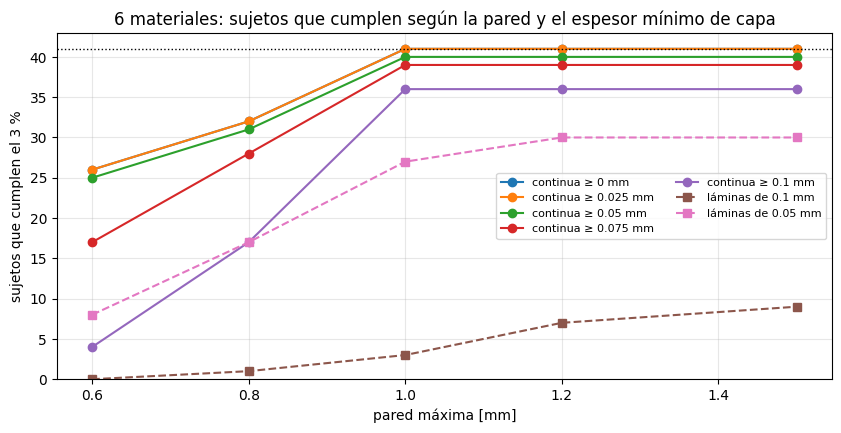


Sujetos que cumplen, 5 vs 6 materiales:
                    5 materiales                 6 materiales                
pared máx. [mm]              0.6 0.8 1.0 1.2 1.5          0.6 0.8 1.0 1.2 1.5
capa                                                                         
continua ≥ 0 mm               27  32  40  41  41           26  32  41  41  41
continua ≥ 0.025 mm           26  31  39  40  40           26  32  41  41  41
continua ≥ 0.05 mm            23  28  36  37  37           25  31  40  40  40
continua ≥ 0.075 mm           20  24  33  34  34           17  28  39  39  39
continua ≥ 0.1 mm             14  19  28  29  29            4  17  36  36  36
láminas de 0.1 mm              0   0   0   2   2            0   1   3   7   9
láminas de 0.05 mm             9  14  19  24  24            8  17  27  30  30


In [29]:
# CELDA 25: ESTUDIO DE PARED — sujetos que cumplen el criterio según la pared máxima y el espesor mínimo de capa
#   Para cada combinación se rediseñan los 41 sujetos (minimax con restricciones) con los módulos E de la Celda 23.
#   ESPESORES_DISCRETOS agrega filas con capas de láminas enteras (p. ej. 0.1 = láminas de 0,1 mm).
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PAREDES_MM = [0.6, 0.8, 1.0, 1.2, 1.5]
ESP_MIN_BARRIDO_MM = [0.0, 0.025, 0.05, 0.075, 0.10]
ESPESORES_DISCRETOS = [0.1, 0.05]

_filas = []
for p in PAREDES_MM:
    for hm, paso in [(hm, None) for hm in ESP_MIN_BARRIDO_MM] + [(t, t) for t in ESPESORES_DISCRETOS]:
        R = [disenar(y, pared=p, hmin=hm, paso=paso or 0) for y in POB_Y]
        e, w = np.array([r[1] for r in R]), np.array([r[0].sum() for r in R])
        _filas.append({"pared máx. [mm]": p, "capa": f"continua ≥ {hm:g} mm" if paso is None else f"láminas de {paso:g} mm",
                       "cumplen 3%": int((e <= ERROR_MAX_PCT).sum()), "error máx. %": e.max(), "error mediano %": np.median(e),
                       "pared mediana [mm]": np.median(w)})
ESTUDIO_PARED = pd.DataFrame(_filas)
ESTUDIO_PARED.to_csv(f"estudio_pared_{VERSION}.csv", index=False)
_tab = ESTUDIO_PARED.pivot(index="capa", columns="pared máx. [mm]", values="cumplen 3%")
_tab = _tab.loc[[f"continua ≥ {hm:g} mm" for hm in ESP_MIN_BARRIDO_MM] + [f"láminas de {t:g} mm" for t in ESPESORES_DISCRETOS]]
print(f"Sujetos (de {len(POB)}) que cumplen el {ERROR_MAX_PCT:g} %, por pared máxima (columnas) y tipo de capa (filas) | E = {E_MAT.round(2).tolist()} MPa:")
print(_tab.to_string())
print("\nError punto a punto máximo entre los 41 sujetos [%]:")
print(ESTUDIO_PARED.pivot(index="capa", columns="pared máx. [mm]", values="error máx. %").loc[_tab.index].round(2).to_string())

fig, ax = plt.subplots(figsize=(10, 4.5))
for capa in _tab.index:
    ax.plot(PAREDES_MM, _tab.loc[capa].to_numpy(), "o-" if capa.startswith("continua") else "s--", label=capa)
ax.axhline(len(POB), color="k", ls=":", lw=1)
ax.set(xlabel="pared máxima [mm]", ylabel=f"sujetos que cumplen el {ERROR_MAX_PCT:g} %", ylim=(0, len(POB) + 2),
       title=f"{N_BASES} materiales: sujetos que cumplen según la pared y el espesor mínimo de capa")
ax.grid(alpha=0.3)
ax.legend(fontsize=8, ncol=2)
plt.savefig(f"estudio_pared_{VERSION}.png", dpi=300, bbox_inches="tight")
plt.show()

_otros = {v: f"estudio_pared_v31_{v}.csv" for v in (5, 6)}
if all(os.path.exists(f) for f in _otros.values()):
    _cmp = pd.concat({f"{v} materiales": pd.read_csv(f).pivot(index="capa", columns="pared máx. [mm]", values="cumplen 3%")
                      for v, f in _otros.items()}, axis=1)
    print("\nSujetos que cumplen, 5 vs 6 materiales:")
    print(_cmp.loc[_tab.index].to_string())

## Celda 26 — Elección de los módulos E de los materiales (opcional)

In [32]:
# CELDA 26 (opcional, ≈ 1 h): ELECCIÓN DE LOS MÓDULOS E DE LOS MATERIALES
#   Busca los E_j que maximizan los sujetos que cumplen el criterio con las restricciones de la Celda 0
#   (desempate: menor error mediano). Evolución diferencial sobre log E. Copiar el resultado en E_REF (Celda 0).
import time
import numpy as np
from scipy.optimize import differential_evolution

OPTIMIZAR_E = False
E_RANGO_MPA = (0.01, 30.0)

if OPTIMIZAR_E:
    _hist = []

    def _obj(logE):
        e = np.array([disenar(y, E=np.exp(logE))[1] for y in POB_Y])
        v = -(e <= ERROR_MAX_PCT).sum() + 0.01 * np.median(np.minimum(e, 50))
        _hist.append((v, np.exp(logE)))
        return v

    t0 = time.time()
    differential_evolution(_obj, [tuple(np.log(E_RANGO_MPA))] * N_BASES, x0=np.log(E_MAT), popsize=8, maxiter=25, seed=SEED,
                           polish=False, init="latinhypercube")
    v, E_OPT = min(_hist, key=lambda t: t[0])
    print(f"✅ {len(_hist)} evaluaciones en {(time.time() - t0) / 60:.0f} min | cumplen {-round(v)}/{len(POB)} sujetos")
    print(f"   copiar en la Celda 0: E_REF[{N_BASES}] = {np.round(E_OPT, 4).tolist()}")
else:
    print(f"OPTIMIZAR_E = False: se usan E = {E_MAT.round(4).tolist()} MPa")

OPTIMIZAR_E = False: se usan E = [0.177, 1.3282, 4.8612, 2.7239, 12.9384, 6.3525] MPa
